# Indonesia Landslide Susceptibility — Modelling and Evaluation

This notebook trains and evaluates machine-learning models using the **Indonesia/Cempaka landslide susceptibility dataset** created by the Indonesia dataset-builder notebook.

The full Indonesia dataset is preserved with all supplied conditioning factors. In accordance with the modelling decision for this experiment, **distance to river (`distriv`) and distance to road (`distroad`) are removed only here, at the modelling stage**.

## Modelling workflow

1. Load the full Indonesia modelling table.
2. Keep the original dataset intact and define the modelling feature set.
3. Exclude only `distriv` and `distroad` from model inputs.
4. Create a stratified train/test split and fit preprocessing on the training data only.
5. Compare baseline classifiers using **5-fold stratified cross-validation on the training set only**.
6. Tune Random Forest and XGBoost using the training set.
7. Select the final candidate using cross-validation performance — **not the held-out test set**.
8. Evaluate tuned models once on the held-out test set using multiple metrics.
9. Visualize confusion matrices, ROC/PR curves, calibration, and learning behaviour.
10. Interpret the selected model using permutation importance and optional SHAP analysis.
11. Perform **spatial cross-validation** as a robustness check against spatial autocorrelation.
12. Save the selected model, preprocessor, feature list, and evaluation results.

> `distriv` and `distroad` remain in `training_table_indonesia_extended.csv`; they are excluded only from the feature list used by this modelling notebook.


## 0. Setup

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
)
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    StratifiedGroupKFold,
    cross_validate,
    RandomizedSearchCV,
    learning_curve,
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    brier_score_loss,
)

from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
    print("XGBoost:", xgb.__version__)
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost is not installed. XGBoost-specific cells will be skipped.")
    print("Install once if needed: pip install xgboost")

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_SPLITS = 5
TEST_SIZE = 0.20

np.random.seed(RANDOM_STATE)

print("Setup complete.")


XGBoost: 3.0.0
Setup complete.


## 1. Load modelling data and metadata

In [2]:
PROJECT_ROOT = Path.cwd().resolve().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

FIGURE_DIR = PROCESSED_DIR / "figures" / "indonesia_modeling"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

FINAL_CSV = PROCESSED_DIR / "training_table_indonesia_extended.csv"
MANIFEST_PATH = PROCESSED_DIR / "indonesia_dataset_manifest.json"

if not FINAL_CSV.exists():
    raise FileNotFoundError(
        f"Indonesia full dataset not found: {FINAL_CSV}\n"
        "Run the Indonesia dataset-builder notebook first."
    )

full_df = pd.read_csv(FINAL_CSV)

manifest = {}
if MANIFEST_PATH.exists():
    manifest = json.loads(
        MANIFEST_PATH.read_text(encoding="utf-8")
    )

# ------------------------------------------------------------------
# Full Indonesia factor set
# distriv and distroad are intentionally kept in the source CSV.
# ------------------------------------------------------------------
FULL_CONTINUOUS_FACTORS = [
    "aspect",
    "distriv",
    "distroad",
    "elev",
    "planc",
    "profc",
    "slope",
    "spi",
    "twi",
]

FULL_CATEGORICAL_FACTORS = [
    "geologi",
    "landuse",
]

MODEL_EXCLUDE_FACTORS = [
    "distriv",
    "distroad",
]

# ------------------------------------------------------------------
# Remove distance-to-river and distance-to-road ONLY FOR MODELLING
# ------------------------------------------------------------------
model_continuous_factors = [
    factor
    for factor in FULL_CONTINUOUS_FACTORS
    if factor not in MODEL_EXCLUDE_FACTORS
]

model_categorical_factors = (
    FULL_CATEGORICAL_FACTORS.copy()
)

model_factor_columns = (
    model_continuous_factors
    + model_categorical_factors
)

required_columns = (
    ["label", "X", "Y"]
    + FULL_CONTINUOUS_FACTORS
    + FULL_CATEGORICAL_FACTORS
)

missing_columns = [
    c for c in required_columns
    if c not in full_df.columns
]

if missing_columns:
    raise ValueError(
        "The Indonesia dataset is missing required columns: "
        + ", ".join(missing_columns)
    )

print("Full Indonesia factors:")
print(FULL_CONTINUOUS_FACTORS + FULL_CATEGORICAL_FACTORS)

print("\nExcluded only at modelling stage:")
print(MODEL_EXCLUDE_FACTORS)

print("\nFinal modelling factors:")
print(model_factor_columns)

assert "distriv" in full_df.columns
assert "distroad" in full_df.columns
assert "distriv" not in model_factor_columns
assert "distroad" not in model_factor_columns

# ------------------------------------------------------------------
# Build modelling table
# ------------------------------------------------------------------
model_input_df = full_df[
    ["label"] + model_factor_columns
].copy()

print("\nRows before missing-value filtering:", len(model_input_df))

model_input_df = model_input_df.dropna(
    subset=model_factor_columns + ["label"]
).copy()

model_input_df["label"] = (
    model_input_df["label"]
    .astype(int)
)

print("Rows after missing-value filtering :", len(model_input_df))

X_raw = model_input_df[model_factor_columns].copy()
y = model_input_df["label"].copy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

# ------------------------------------------------------------------
# Training-only preprocessing
# ------------------------------------------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        (
            "continuous",
            StandardScaler(),
            model_continuous_factors,
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
            model_categorical_factors,
        ),
    ],
    remainder="drop",
)

X_train_array = preprocessor.fit_transform(X_train_raw)
X_test_array = preprocessor.transform(X_test_raw)

processed_feature_names = (
    preprocessor.get_feature_names_out()
)

X_train = pd.DataFrame(
    X_train_array,
    columns=processed_feature_names,
    index=X_train_raw.index,
)

X_test = pd.DataFrame(
    X_test_array,
    columns=processed_feature_names,
    index=X_test_raw.index,
)

# Reset index only after preserving the aligned split
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
X_train_raw = X_train_raw.reset_index(drop=True)
X_test_raw = X_test_raw.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

# ------------------------------------------------------------------
# Visual style retained from the Kerala modelling notebook
# ------------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")

PRIMARY = "#1F4E79"
SECONDARY = "#2E7D6E"
ACCENT = "#B7791F"
DANGER = "#A63D40"
SLATE = "#44546A"
PURPLE = "#6A4C93"
ORANGE = "#C65D24"
GREEN = "#3A6B35"
PINK = "#9A4D6A"
CYAN = "#28788A"

LIGHT = "#F7F8FA"
GRID = "#D5DAE0"

CLASS_COLORS = {
    "Non-landslide": "#2F5597",
    "Landslide": "#C43C3C",
}

MODEL_COLORS = [
    "#1F4E79",
    "#2E7D6E",
    "#6A4C93",
    "#C65D24",
    "#A63D40",
    "#28788A",
    "#3A6B35",
    "#9A4D6A",
]

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.edgecolor": "#94A3B8",
    "axes.linewidth": 0.9,
    "grid.color": GRID,
    "grid.alpha": 0.60,
    "grid.linewidth": 0.7,
    "legend.frameon": False,
    "font.size": 10.5,
})

def polish_axes(
    ax,
    title=None,
    xlabel=None,
    ylabel=None,
):
    if title:
        ax.set_title(
            title,
            loc="left",
            pad=14,
        )

    if xlabel is not None:
        ax.set_xlabel(xlabel)

    if ylabel is not None:
        ax.set_ylabel(ylabel)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)

    return ax

def save_figure(fig, filename):
    path = FIGURE_DIR / filename
    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )
    print("Saved figure:", path)
    return path

print("\nProject root :", PROJECT_ROOT)
print("Processed dir:", PROCESSED_DIR)
print("Figure dir   :", FIGURE_DIR)
print()
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)
print("Raw train:", X_train_raw.shape)
print("Raw test :", X_test_raw.shape)
print("Processed features:", X_train.shape[1])


Full Indonesia factors:
['aspect', 'distriv', 'distroad', 'elev', 'planc', 'profc', 'slope', 'spi', 'twi', 'geologi', 'landuse']

Excluded only at modelling stage:
['distriv', 'distroad']

Final modelling factors:
['aspect', 'elev', 'planc', 'profc', 'slope', 'spi', 'twi', 'geologi', 'landuse']

Rows before missing-value filtering: 1486
Rows after missing-value filtering : 1485

Project root : D:\PROJECTS\Landslide_prediction
Processed dir: D:\PROJECTS\Landslide_prediction\data\processed
Figure dir   : D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling

X_train: (1188, 31) | y_train: (1188,)
X_test : (297, 31) | y_test : (297,)
Raw train: (1188, 9)
Raw test : (297, 9)
Processed features: 31


### 1.1 Data integrity and class-balance check

Missing values in processed train: 0
Missing values in processed test : 0


,Train,Test
Non-landslide,594,148
Landslide,594,149


Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\01_class_balance.png


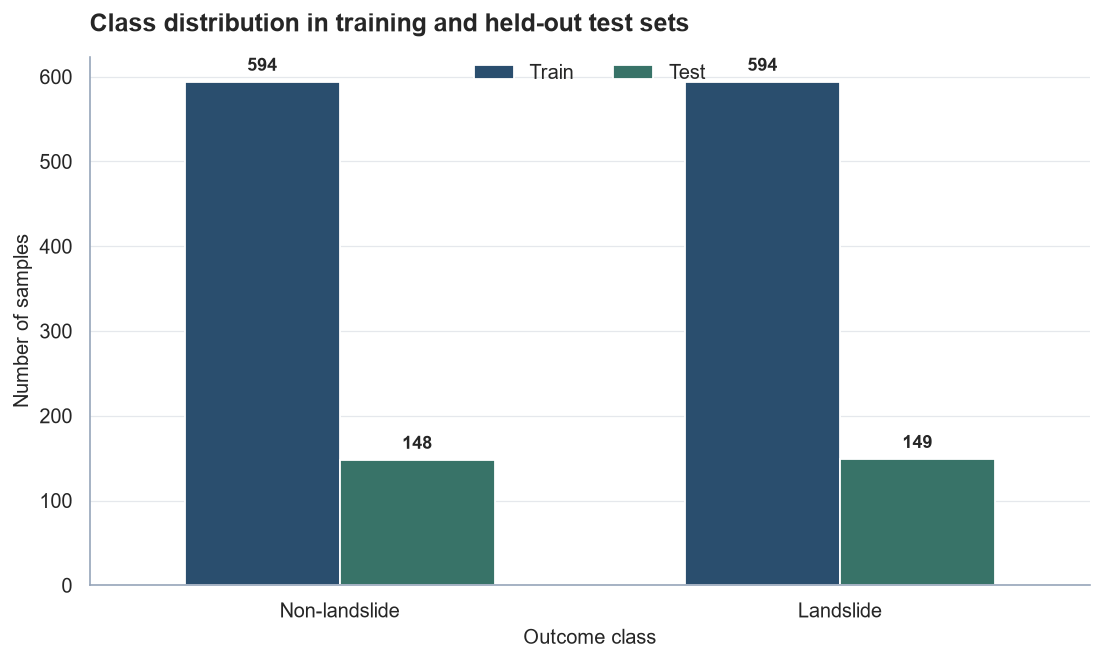

In [3]:
assert len(X_train) == len(y_train), "X_train/y_train row mismatch."
assert len(X_test) == len(y_test), "X_test/y_test row mismatch."
assert list(X_train.columns) == list(X_test.columns), "Processed train/test columns differ."
assert list(X_train_raw.columns) == list(X_test_raw.columns), "Raw train/test columns differ."

print("Missing values in processed train:", int(X_train.isna().sum().sum()))
print("Missing values in processed test :", int(X_test.isna().sum().sum()))

class_summary = pd.DataFrame({
    "Train": y_train.value_counts().sort_index(),
    "Test": y_test.value_counts().sort_index(),
}).fillna(0).astype(int)

class_summary.index = [
    "Non-landslide" if i == 0 else "Landslide"
    for i in class_summary.index
]

display(class_summary)

plot_df = (
    class_summary
    .reset_index(names="Class")
    .melt(id_vars="Class", var_name="Dataset", value_name="Samples")
)

fig, ax = plt.subplots(figsize=(8.6, 5.2))
sns.barplot(
    data=plot_df,
    x="Class",
    y="Samples",
    hue="Dataset",
    palette=[PRIMARY, SECONDARY],
    width=0.62,
    ax=ax,
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=4, fontsize=10, fontweight="bold")

polish_axes(
    ax,
    "Class distribution in training and held-out test sets",
    "Outcome class",
    "Number of samples",
)
ax.legend(title="", ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.02))
ax.grid(axis="x", visible=False)

fig.tight_layout()
save_figure(fig, "01_class_balance.png")
plt.show()


### 1.2 Conditioning-factor summary

,Factor type,Count
0,Continuous,7
1,Categorical,2


Continuous modelling factors : ['aspect', 'elev', 'planc', 'profc', 'slope', 'spi', 'twi']
Categorical modelling factors: ['geologi', 'landuse']
Excluded at modelling stage  : ['distriv', 'distroad']
Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\02_factor_family_summary.png


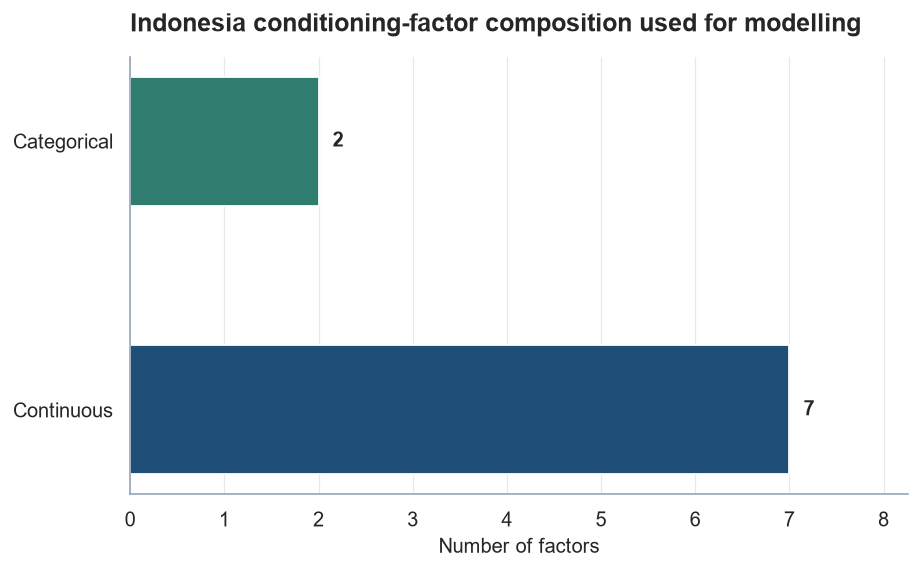

In [4]:
continuous_factors = model_continuous_factors.copy()
categorical_factors = model_categorical_factors.copy()

factor_family_summary = pd.DataFrame({
    "Factor type": ["Continuous", "Categorical"],
    "Count": [len(continuous_factors), len(categorical_factors)],
})

display(factor_family_summary)

print("Continuous modelling factors :", continuous_factors)
print("Categorical modelling factors:", categorical_factors)
print("Excluded at modelling stage  :", MODEL_EXCLUDE_FACTORS)

fig, ax = plt.subplots(figsize=(7.2, 4.5))

bars = ax.barh(
    factor_family_summary["Factor type"],
    factor_family_summary["Count"],
    color=[PRIMARY, SECONDARY],
    height=0.48,
)

for bar in bars:
    ax.text(
        bar.get_width() + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width())}",
        va="center",
        fontsize=11,
        fontweight="bold",
    )

polish_axes(
    ax,
    "Indonesia conditioning-factor composition used for modelling",
    "Number of factors",
    "",
)

ax.grid(axis="y", visible=False)
ax.set_xlim(
    0,
    max(factor_family_summary["Count"]) * 1.18,
)

fig.tight_layout()
save_figure(
    fig,
    "02_factor_family_summary.png",
)
plt.show()


## 2. Baseline model comparison

All baseline models are compared using the **same 5-fold stratified cross-validation folds** on the training set.

The processed feature matrix is used here because it already applies the training-fitted scaling and categorical encoding created in the dataset-builder notebook.

The held-out test set is **not used** in this section.

In [5]:
candidate_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE,
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
    ),
    "SVM (RBF)": SVC(
        probability=True,
        random_state=RANDOM_STATE,
    ),
    "MLP (Neural Network)": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=800,
        random_state=RANDOM_STATE,
    ),
}

if XGBOOST_AVAILABLE:
    candidate_models["XGBoost"] = xgb.XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=1,
    )

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

cv_summary_rows = []
cv_fold_rows = []

for name, model in candidate_models.items():
    print(f"Running 5-fold CV: {name}")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1,
    )

    summary = {"model": name}

    for metric in scoring:
        summary[f"{metric}_mean"] = scores[f"test_{metric}"].mean()
        summary[f"{metric}_std"] = scores[f"test_{metric}"].std()

    summary["train_f1_mean"] = scores["train_f1"].mean()
    summary["f1_gap"] = summary["train_f1_mean"] - summary["f1_mean"]
    cv_summary_rows.append(summary)

    for fold in range(N_SPLITS):
        cv_fold_rows.append({
            "model": name,
            "fold": fold + 1,
            "accuracy": scores["test_accuracy"][fold],
            "precision": scores["test_precision"][fold],
            "recall": scores["test_recall"][fold],
            "f1": scores["test_f1"][fold],
            "roc_auc": scores["test_roc_auc"][fold],
        })

cv_results_df = (
    pd.DataFrame(cv_summary_rows)
    .sort_values("f1_mean", ascending=False)
    .reset_index(drop=True)
)

cv_fold_df = pd.DataFrame(cv_fold_rows)

display(cv_results_df.round(4))

Running 5-fold CV: Logistic Regression
Running 5-fold CV: Decision Tree
Running 5-fold CV: Random Forest
Running 5-fold CV: Gradient Boosting
Running 5-fold CV: SVM (RBF)
Running 5-fold CV: MLP (Neural Network)
Running 5-fold CV: XGBoost


,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,train_f1_mean,f1_gap
0,SVM (RBF),0.6869,0.0160,0.6763,0.0278,0.7239,0.0410,0.6978,0.0135,0.7538,0.0150,0.7870,0.0892
1,Random Forest,0.6843,0.0126,0.6788,0.0193,0.7036,0.0454,0.6898,0.0175,0.7638,0.0100,1.0000,0.3102
2,Gradient Boosting,0.6785,0.0183,0.6730,0.0219,0.6969,0.0458,0.6837,0.0228,0.7305,0.0090,0.9659,0.2822
3,XGBoost,0.6759,0.0220,0.6734,0.0189,0.6852,0.0595,0.6778,0.0307,0.7412,0.0131,0.9985,0.3208
4,Logistic Regression,0.6608,0.0156,0.6516,0.0255,0.6986,0.0402,0.6729,0.0122,0.7206,0.0199,0.6994,0.0266
5,Decision Tree,0.6499,0.0473,0.6477,0.0489,0.6750,0.1118,0.6549,0.0576,0.6746,0.0517,0.8517,0.1968
6,MLP (Neural Network),0.6439,0.0181,0.6402,0.0271,0.6634,0.0223,0.6508,0.0107,0.6841,0.0274,1.0000,0.3492


### Visualization standard

All modelling figures use a consistent thesis-ready visual style with readable typography, restrained colour use, direct metric annotation, and **300-DPI PNG export** to `data/processed/figures/indonesia_modeling/`.


### 2.1 Baseline-performance heatmap

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\03_baseline_cv_heatmap.png


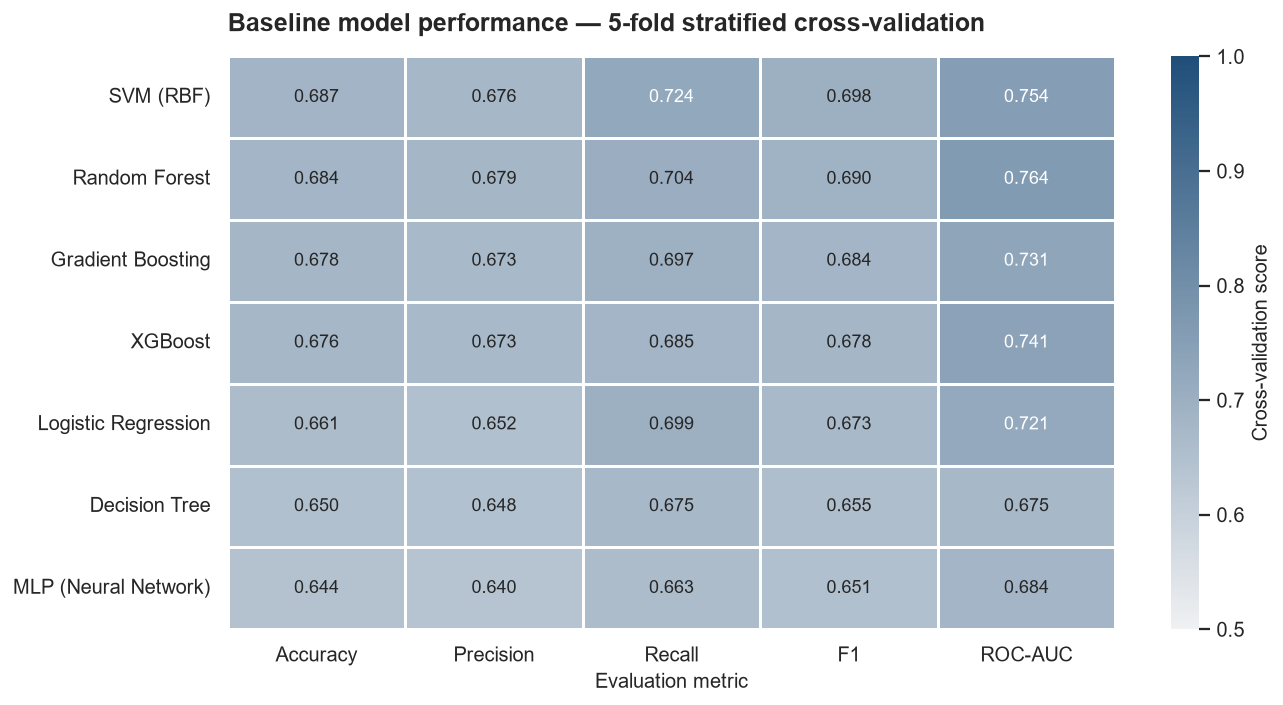

In [6]:
baseline_metrics = [
    "accuracy_mean",
    "precision_mean",
    "recall_mean",
    "f1_mean",
    "roc_auc_mean",
]

heatmap_df = (
    cv_results_df
    .set_index("model")[baseline_metrics]
    .rename(columns={
        "accuracy_mean": "Accuracy",
        "precision_mean": "Precision",
        "recall_mean": "Recall",
        "f1_mean": "F1",
        "roc_auc_mean": "ROC-AUC",
    })
)

fig, ax = plt.subplots(figsize=(10.5, max(4.6, 0.62 * len(heatmap_df) + 1.2)))
cmap = sns.light_palette(PRIMARY, as_cmap=True)

sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".3f",
    vmin=0.5,
    vmax=1.0,
    cmap=cmap,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Cross-validation score"},
    annot_kws={"fontsize": 10},
    ax=ax,
)

ax.set_title("Baseline model performance — 5-fold stratified cross-validation", loc="left", pad=14, fontweight="bold")
ax.set_xlabel("Evaluation metric")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()
save_figure(fig, "03_baseline_cv_heatmap.png")
plt.show()


### 2.2 Fold-to-fold stability

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\04_cv_f1_stability.png


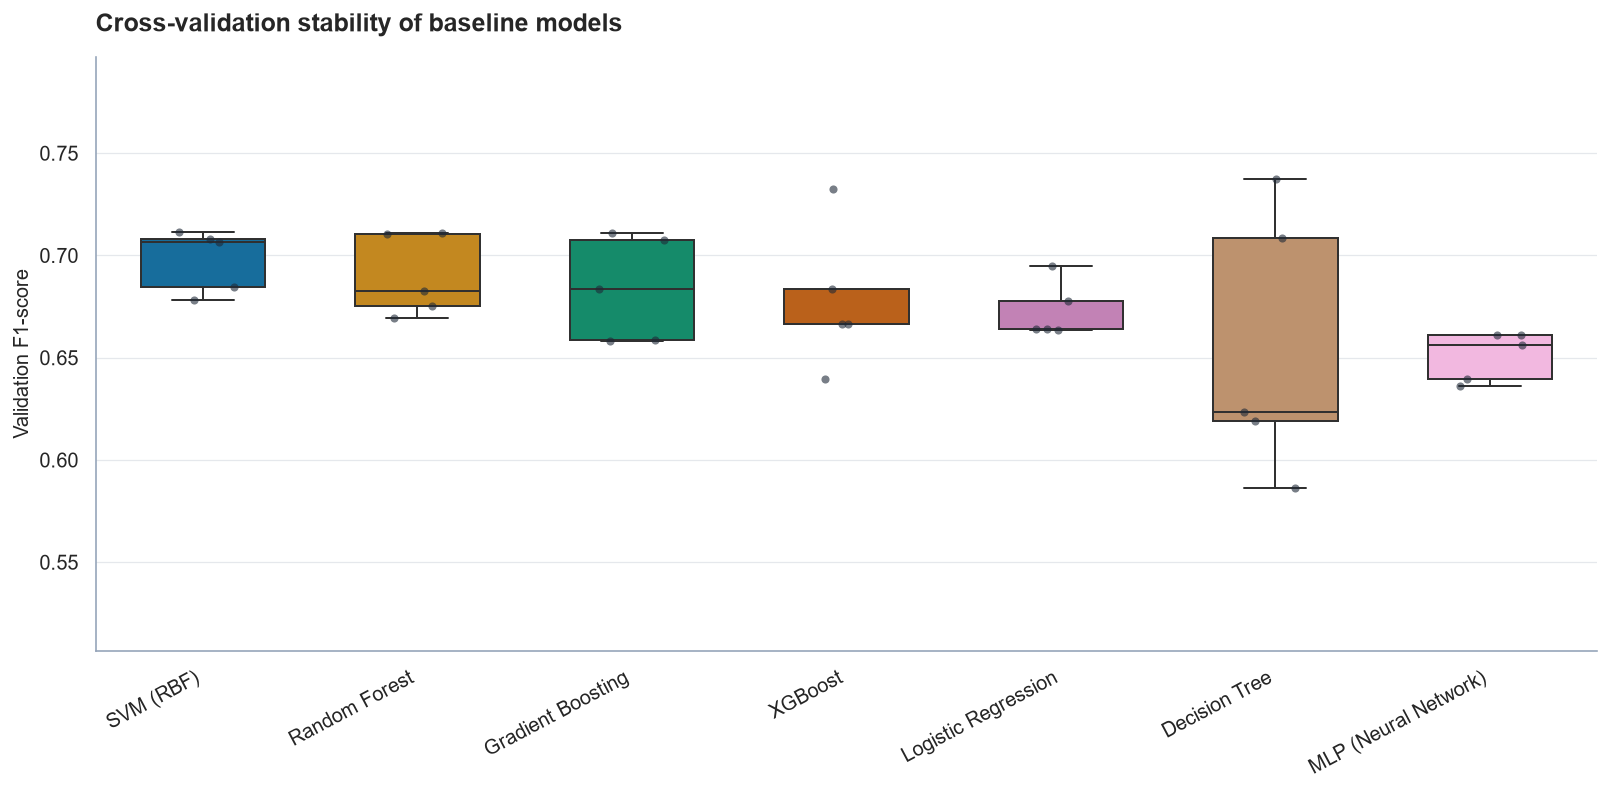

In [7]:
model_order = (
    cv_results_df
    .sort_values("f1_mean", ascending=False)["model"]
    .tolist()
)

model_palette = dict(
    zip(
        model_order,
        sns.color_palette("colorblind", n_colors=len(model_order))
    )
)

fig, ax = plt.subplots(figsize=(12.5, 6.2))

sns.boxplot(
    data=cv_fold_df,
    x="model",
    y="f1",
    order=model_order,
    palette=model_palette,
    width=0.58,
    linewidth=1.1,
    fliersize=0,
    ax=ax,
)

sns.stripplot(
    data=cv_fold_df,
    x="model",
    y="f1",
    order=model_order,
    color="#1F2937",
    size=4.5,
    alpha=0.6,
    jitter=0.16,
    ax=ax,
)

polish_axes(
    ax,
    "Cross-validation stability of baseline models",
    "",
    "Validation F1-score",
)
ax.set_ylim(max(0, cv_fold_df["f1"].min() - 0.08), min(1.0, cv_fold_df["f1"].max() + 0.06))
ax.tick_params(axis="x", rotation=28)
for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

fig.tight_layout()
save_figure(fig, "04_cv_f1_stability.png")
plt.show()


### 2.3 Training-versus-validation F1 gap

,model,train_f1_mean,f1_mean,f1_gap
6,MLP (Neural Network),1.0000,0.6508,0.3492
5,XGBoost,0.9985,0.6778,0.3208
4,Random Forest,1.0000,0.6898,0.3102
3,Gradient Boosting,0.9659,0.6837,0.2822
2,Decision Tree,0.8517,0.6549,0.1968
1,SVM (RBF),0.7870,0.6978,0.0892
0,Logistic Regression,0.6994,0.6729,0.0266


Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\05_training_validation_gap.png


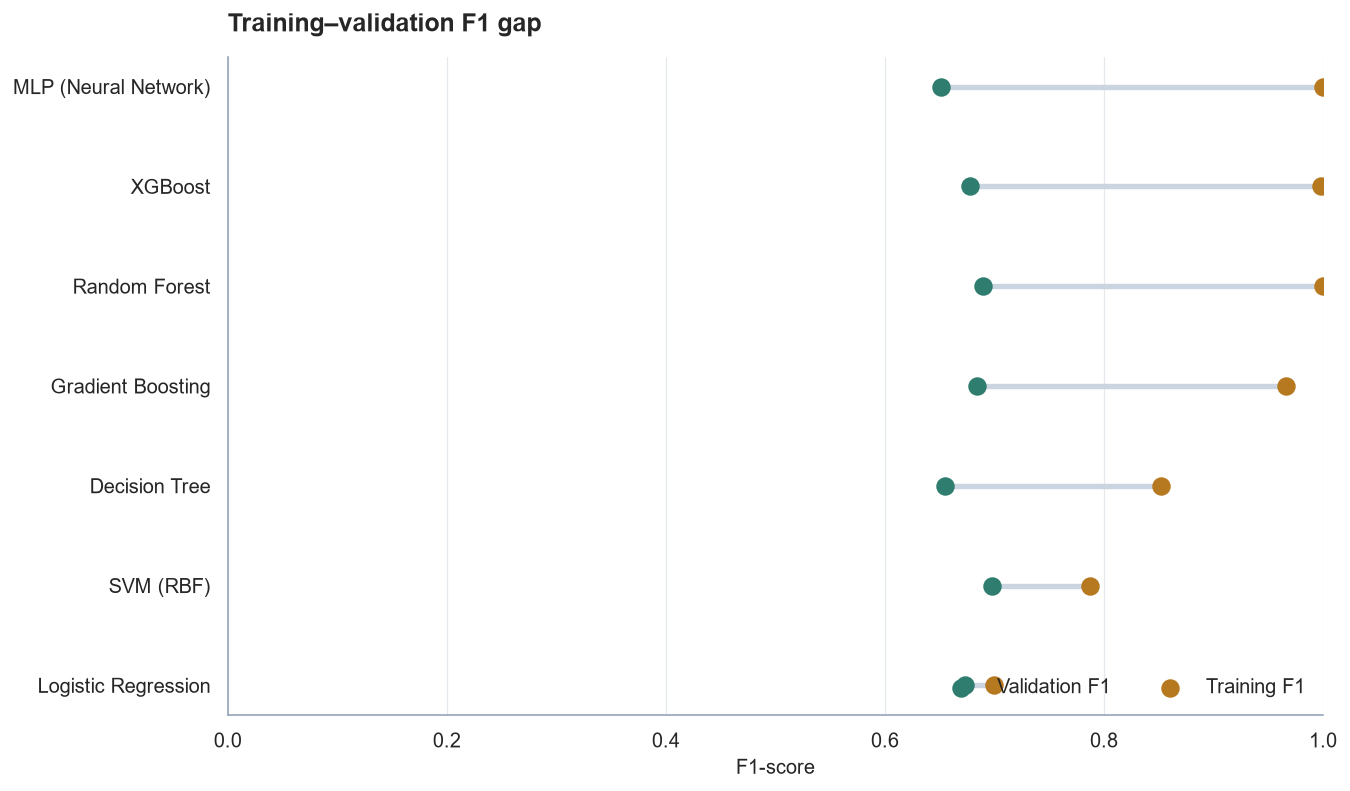

In [8]:
gap_df = (
    cv_results_df[
        ["model", "train_f1_mean", "f1_mean", "f1_gap"]
    ]
    .sort_values("f1_gap", ascending=True)
    .reset_index(drop=True)
)

display(gap_df.sort_values("f1_gap", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(10.5, 6.2))
y_pos = np.arange(len(gap_df))

for i, row in gap_df.iterrows():
    ax.plot(
        [row["f1_mean"], row["train_f1_mean"]],
        [i, i],
        color="#CBD5E1",
        linewidth=3,
        zorder=1,
    )

ax.scatter(
    gap_df["f1_mean"],
    y_pos,
    s=85,
    color=SECONDARY,
    label="Validation F1",
    zorder=3,
)
ax.scatter(
    gap_df["train_f1_mean"],
    y_pos,
    s=85,
    color=ACCENT,
    label="Training F1",
    zorder=3,
)

ax.set_yticks(y_pos)
ax.set_yticklabels(gap_df["model"])
ax.set_xlim(0, 1)

polish_axes(
    ax,
    "Training–validation F1 gap",
    "F1-score",
    "",
)
ax.legend(loc="lower right", ncol=2)
ax.grid(axis="y", visible=False)

fig.tight_layout()
save_figure(fig, "05_training_validation_gap.png")
plt.show()


## 3. Hyperparameter tuning

Random Forest and XGBoost are tuned using `RandomizedSearchCV` on the training set.

The optimization metric is **F1-score**, which balances precision and recall for the binary landslide/non-landslide task.

In [9]:
# Random Forest tuning

rf_param_dist = {
    "n_estimators": [200, 300, 500, 800],
    "max_depth": [None, 8, 12, 16, 24],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None],
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    param_distributions=rf_param_dist,
    n_iter=25,
    scoring="f1",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)

rf_search.fit(X_train, y_train)

print("Best RF parameters:")
print(rf_search.best_params_)
print("Best RF CV F1:", round(rf_search.best_score_, 4))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best RF parameters:
{'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 8}
Best RF CV F1: 0.705


In [10]:
# XGBoost tuning

xgb_search = None

if XGBOOST_AVAILABLE:
    xgb_param_dist = {
        "n_estimators": [200, 300, 500, 800],
        "max_depth": [3, 4, 6, 8, 10],
        "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
        "subsample": [0.6, 0.8, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "min_child_weight": [1, 3, 5],
    }

    xgb_search = RandomizedSearchCV(
        estimator=xgb.XGBClassifier(
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=1,
        ),
        param_distributions=xgb_param_dist,
        n_iter=25,
        scoring="f1",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1,
        return_train_score=True,
    )

    xgb_search.fit(X_train, y_train)

    print("Best XGBoost parameters:")
    print(xgb_search.best_params_)
    print("Best XGBoost CV F1:", round(xgb_search.best_score_, 4))
else:
    print("XGBoost tuning skipped because xgboost is not installed.")

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best XGBoost parameters:
{'subsample': 0.6, 'n_estimators': 800, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 0.6}
Best XGBoost CV F1: 0.6942


### 3.1 Select the final candidate using training CV only

,Model,Best CV F1
1,Random Forest (tuned),0.7050
0,XGBoost (tuned),0.6942


Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\06_tuned_model_selection.png


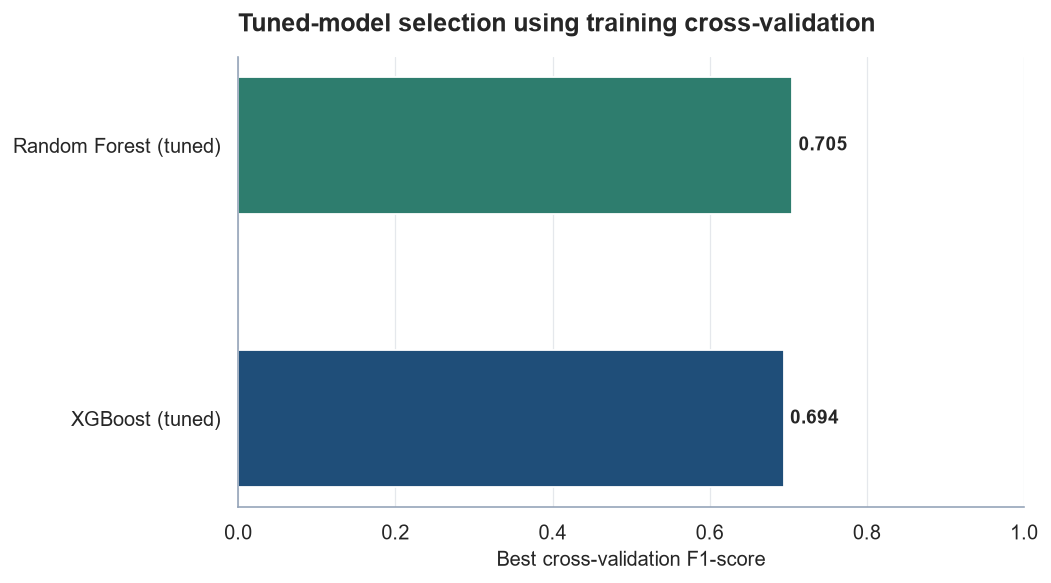

Selected final candidate: Random Forest (tuned)
Selection criterion: highest training cross-validation F1.


In [11]:
tuned_models = {
    "Random Forest (tuned)": rf_search.best_estimator_,
}

tuned_cv_f1 = {
    "Random Forest (tuned)": rf_search.best_score_,
}

if xgb_search is not None:
    tuned_models["XGBoost (tuned)"] = xgb_search.best_estimator_
    tuned_cv_f1["XGBoost (tuned)"] = xgb_search.best_score_

selected_name = max(
    tuned_cv_f1,
    key=tuned_cv_f1.get,
)

selected_model = tuned_models[selected_name]

selection_df = (
    pd.DataFrame({
        "Model": list(tuned_cv_f1.keys()),
        "Best CV F1": list(tuned_cv_f1.values()),
    })
    .sort_values("Best CV F1", ascending=True)
    .reset_index(drop=True)
)

display(selection_df.sort_values("Best CV F1", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(8.2, 4.6))
colors = [
    SECONDARY if model == selected_name else PRIMARY
    for model in selection_df["Model"]
]
bars = ax.barh(
    selection_df["Model"],
    selection_df["Best CV F1"],
    color=colors,
    height=0.5,
)

for bar, value in zip(bars, selection_df["Best CV F1"]):
    ax.text(
        value + 0.008,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        fontweight="bold",
    )

polish_axes(
    ax,
    "Tuned-model selection using training cross-validation",
    "Best cross-validation F1-score",
    "",
)
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)

fig.tight_layout()
save_figure(fig, "06_tuned_model_selection.png")
plt.show()

print("Selected final candidate:", selected_name)
print("Selection criterion: highest training cross-validation F1.")


## 4. Held-out test evaluation

The held-out test set is now used **for the first time** to estimate final predictive performance.

In addition to accuracy, the notebook reports precision, recall/sensitivity, specificity, F1, MCC, TSS, ROC-AUC, and PR-AUC.

In [12]:
def evaluate_binary_classifier(model, X, y):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y, y_pred, labels=[0, 1]).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan
    tss = sensitivity + specificity - 1

    return {
        "accuracy": accuracy_score(y, y_pred),
        "precision": precision_score(y, y_pred, zero_division=0),
        "recall": recall_score(y, y_pred, zero_division=0),
        "specificity": specificity,
        "f1": f1_score(y, y_pred, zero_division=0),
        "mcc": matthews_corrcoef(y, y_pred),
        "tss": tss,
        "roc_auc": roc_auc_score(y, y_proba),
        "pr_auc": average_precision_score(y, y_proba),
        "brier": brier_score_loss(y, y_proba),
    }


test_rows = []

for name, model in tuned_models.items():
    result = evaluate_binary_classifier(
        model,
        X_test,
        y_test,
    )
    result["model"] = name
    test_rows.append(result)

final_results_df = (
    pd.DataFrame(test_rows)
    .set_index("model")
    .sort_values("f1", ascending=False)
)

display(final_results_df.round(4))

print("\nFinal candidate selected BEFORE test evaluation:", selected_name)
print("\nClassification report:")
print(
    classification_report(
        y_test,
        selected_model.predict(X_test),
        target_names=["Non-landslide", "Landslide"],
        digits=4,
    )
)

,accuracy,precision,recall,specificity,f1,mcc,tss,roc_auc,pr_auc,brier
model,,,,,,,,,,
Random Forest (tuned),0.6869,0.6867,0.6913,0.6824,0.6890,0.3737,0.3737,0.7729,0.7493,0.1958
XGBoost (tuned),0.6801,0.6753,0.6980,0.6622,0.6865,0.3604,0.3601,0.7687,0.7627,0.1959



Final candidate selected BEFORE test evaluation: Random Forest (tuned)

Classification report:
               precision    recall  f1-score   support

Non-landslide     0.6871    0.6824    0.6847       148
    Landslide     0.6867    0.6913    0.6890       149

     accuracy                         0.6869       297
    macro avg     0.6869    0.6869    0.6869       297
 weighted avg     0.6869    0.6869    0.6869       297



### 4.1 Held-out metric heatmap

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\07_heldout_metric_heatmap.png


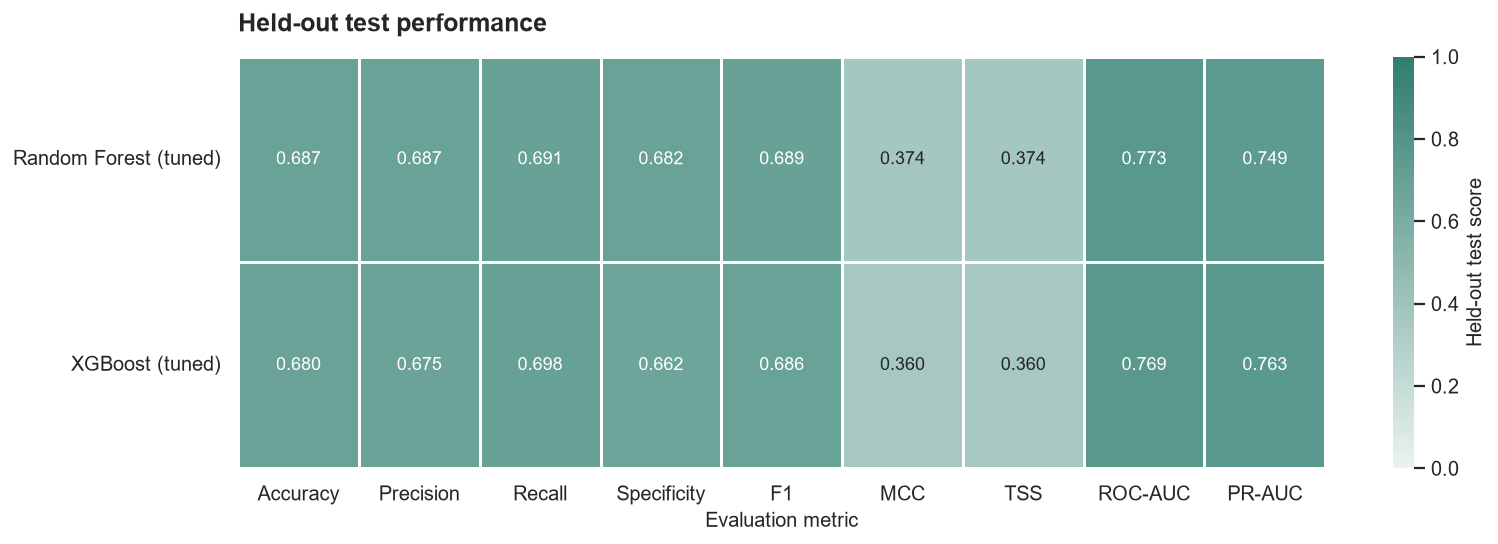

In [13]:
metric_cols = [
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "mcc",
    "tss",
    "roc_auc",
    "pr_auc",
]

metric_labels = {
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "specificity": "Specificity",
    "f1": "F1",
    "mcc": "MCC",
    "tss": "TSS",
    "roc_auc": "ROC-AUC",
    "pr_auc": "PR-AUC",
}

heldout_plot = final_results_df[metric_cols].rename(columns=metric_labels)

fig, ax = plt.subplots(figsize=(12.5, max(4.3, 1.25 * len(heldout_plot) + 1.2)))
cmap = sns.light_palette(SECONDARY, as_cmap=True)

sns.heatmap(
    heldout_plot,
    annot=True,
    fmt=".3f",
    vmin=0,
    vmax=1,
    cmap=cmap,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Held-out test score"},
    annot_kws={"fontsize": 10},
    ax=ax,
)

ax.set_title("Held-out test performance", loc="left", pad=14, fontweight="bold")
ax.set_xlabel("Evaluation metric")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()
save_figure(fig, "07_heldout_metric_heatmap.png")
plt.show()


### 4.2 Confusion matrices

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\08_confusion_matrices.png


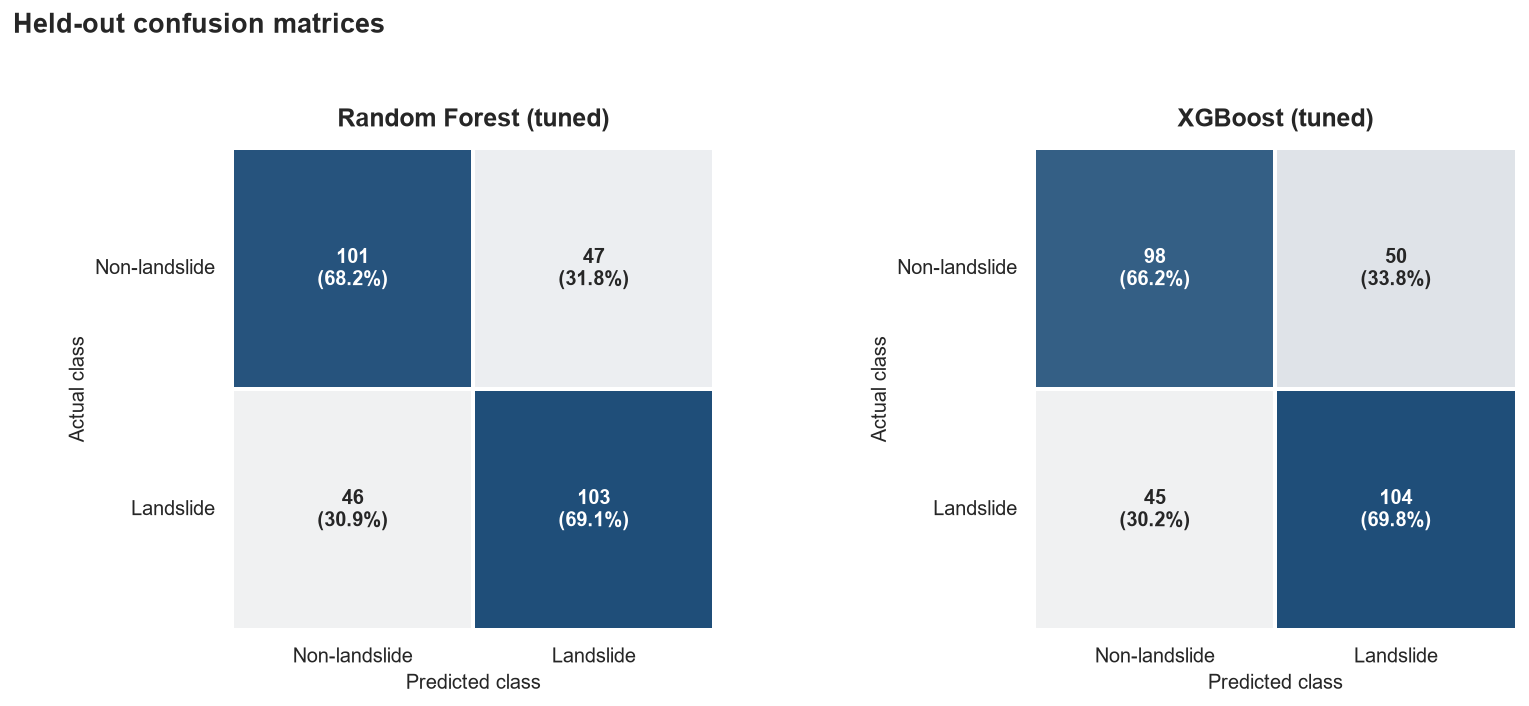

In [14]:
n_models = len(tuned_models)

fig, axes = plt.subplots(
    1,
    n_models,
    figsize=(6.3 * n_models, 5.5),
)

axes = np.atleast_1d(axes)

for ax, (name, model) in zip(axes, tuned_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    # Row-normalized percentages for easier interpretation
    row_pct = cm / cm.sum(axis=1, keepdims=True)
    labels = np.array([
        [f"{cm[i, j]:,}\n({row_pct[i, j]:.1%})" for j in range(2)]
        for i in range(2)
    ])

    sns.heatmap(
        cm,
        annot=labels,
        fmt="",
        cmap=sns.light_palette(PRIMARY, as_cmap=True),
        cbar=False,
        linewidths=1.2,
        linecolor="white",
        square=True,
        xticklabels=["Non-landslide", "Landslide"],
        yticklabels=["Non-landslide", "Landslide"],
        annot_kws={"fontsize": 11, "fontweight": "bold"},
        ax=ax,
    )

    ax.set_title(name, pad=12, fontweight="bold")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle(
    "Held-out confusion matrices",
    x=0.02,
    ha="left",
    fontsize=15,
    fontweight="bold",
)
fig.tight_layout(rect=[0, 0, 1, 0.94])
save_figure(fig, "08_confusion_matrices.png")
plt.show()


### 4.3 ROC curves

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\roc_curves_test_set.png


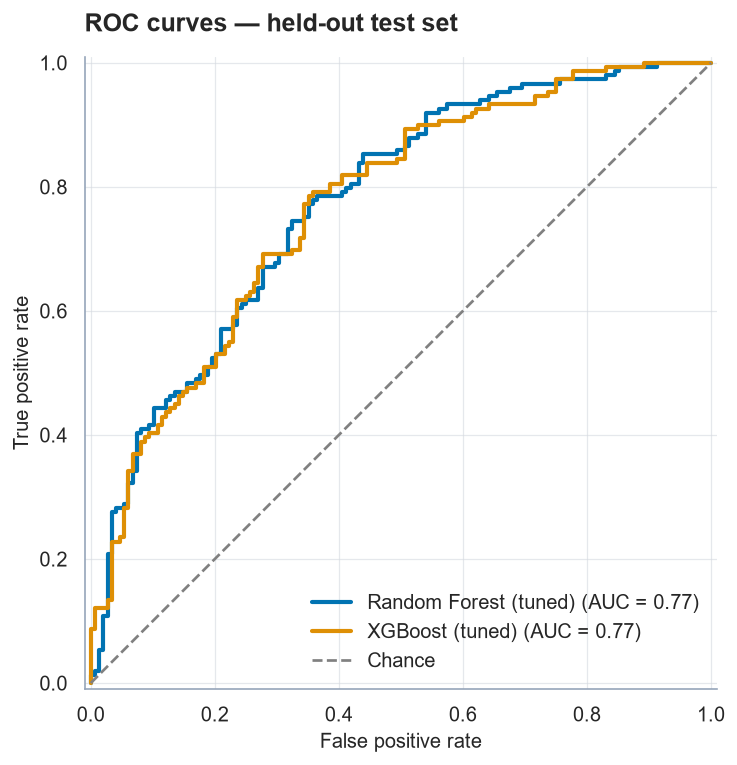

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))

curve_colors = sns.color_palette(
    "colorblind",
    n_colors=len(tuned_models)
)

for color, (name, model) in zip(
    curve_colors,
    tuned_models.items()
):
    display = RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        ax=ax,
        name=name,
    )

    # Apply styling after creating the curve
    display.line_.set_color(color)
    display.line_.set_linewidth(2.3)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    color="gray",
    label="Chance",
)

polish_axes(
    ax,
    "ROC curves — held-out test set",
    "False positive rate",
    "True positive rate",
)

ax.legend()
fig.tight_layout()

save_figure(
    fig,
    "roc_curves_test_set.png",
)

plt.show()

### 4.4 Precision–Recall curves

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\10_precision_recall_curves.png


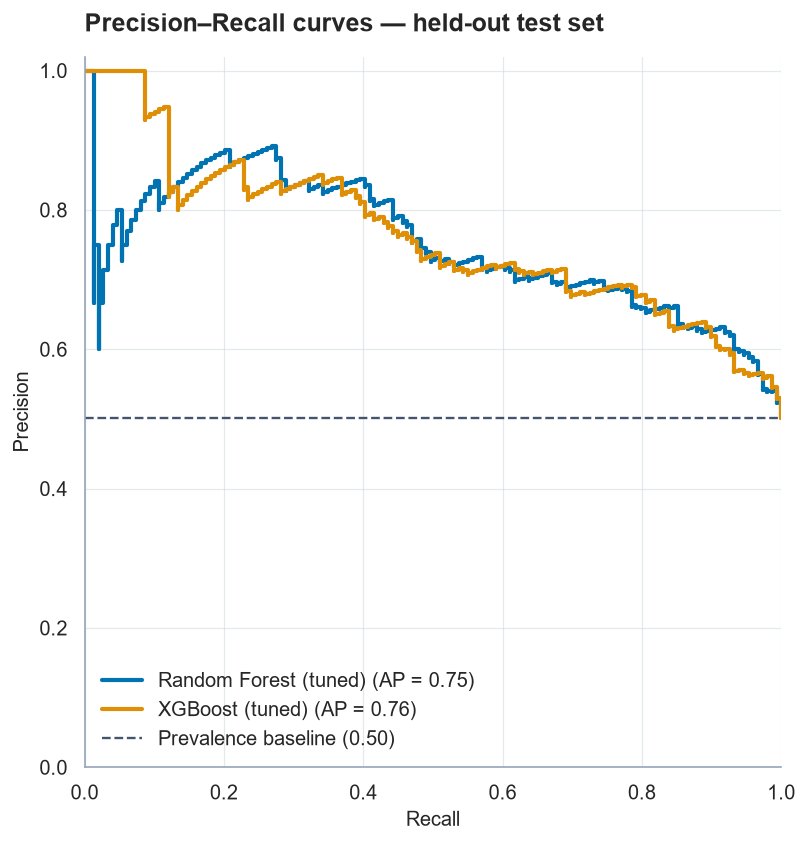

In [17]:
fig, ax = plt.subplots(figsize=(7.8, 6.6))

curve_colors = sns.color_palette("colorblind", n_colors=len(tuned_models))

for color, (name, model) in zip(curve_colors, tuned_models.items()):
    PrecisionRecallDisplay.from_estimator(
        model,
        X_test,
        y_test,
        ax=ax,
        name=name,
        color=color,
        linewidth=2.3,
    )

baseline_precision = float(np.mean(y_test))
ax.axhline(
    baseline_precision,
    linestyle="--",
    linewidth=1.3,
    color=SLATE,
    label=f"Prevalence baseline ({baseline_precision:.2f})",
)

polish_axes(
    ax,
    "Precision–Recall curves — held-out test set",
    "Recall",
    "Precision",
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower left")

fig.tight_layout()
save_figure(fig, "10_precision_recall_curves.png")
plt.show()


### 4.5 Probability calibration of the selected model

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\11_calibration_curve.png


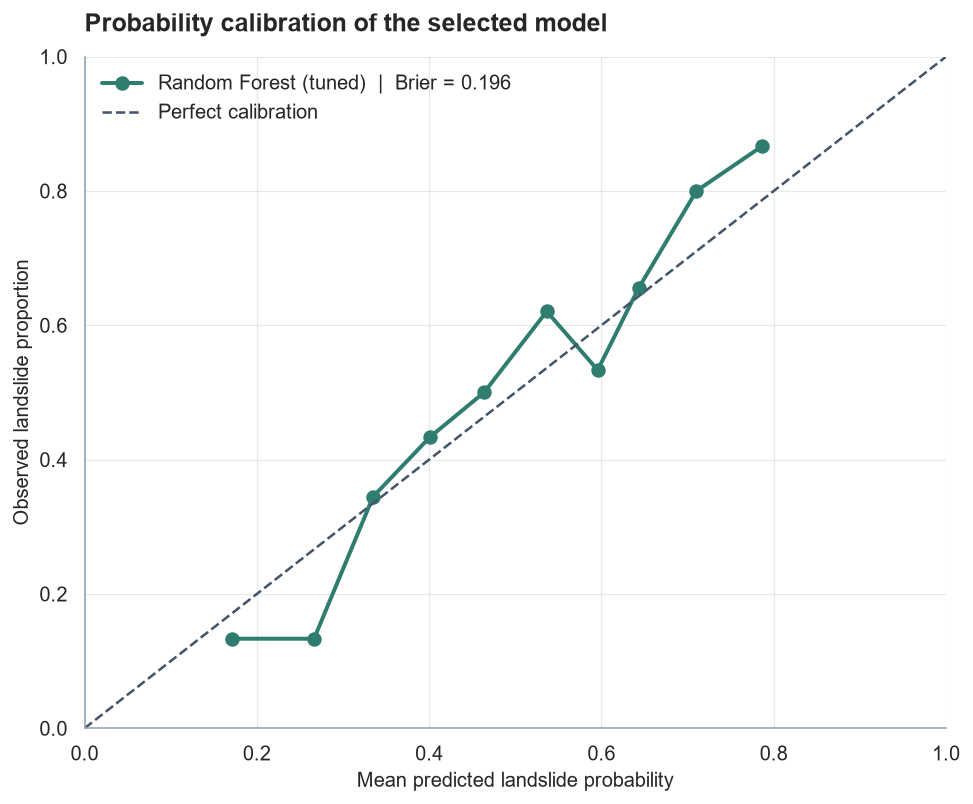

Brier score: 0.1958
Lower Brier scores indicate better probability calibration.


In [18]:
selected_proba = selected_model.predict_proba(X_test)[:, 1]

prob_true, prob_pred = calibration_curve(
    y_test,
    selected_proba,
    n_bins=10,
    strategy="quantile",
)

brier = brier_score_loss(y_test, selected_proba)

fig, ax = plt.subplots(figsize=(7.6, 6.3))
ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    markersize=7,
    linewidth=2.2,
    color=SECONDARY,
    label=f"{selected_name}  |  Brier = {brier:.3f}",
)
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.4,
    color=SLATE,
    label="Perfect calibration",
)

polish_axes(
    ax,
    "Probability calibration of the selected model",
    "Mean predicted landslide probability",
    "Observed landslide proportion",
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc="upper left")

fig.tight_layout()
save_figure(fig, "11_calibration_curve.png")
plt.show()

print("Brier score:", round(brier, 4))
print("Lower Brier scores indicate better probability calibration.")


### 4.6 Learning curve — sample-size and overfitting check

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\12_learning_curve.png


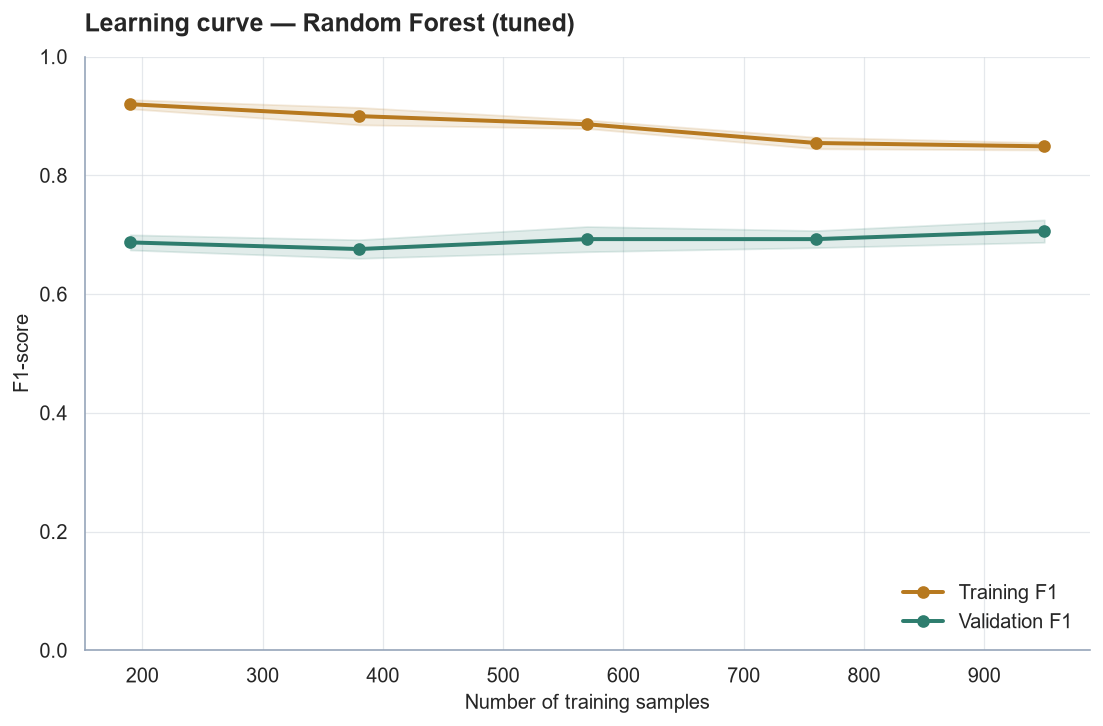

In [19]:
train_sizes, train_scores, valid_scores = learning_curve(
    estimator=clone(selected_model),
    X=X_train,
    y=y_train,
    cv=cv,
    scoring="f1",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1,
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
valid_mean = valid_scores.mean(axis=1)
valid_std = valid_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(8.6, 5.7))

ax.plot(
    train_sizes,
    train_mean,
    marker="o",
    markersize=6,
    linewidth=2.2,
    color=ACCENT,
    label="Training F1",
)
ax.plot(
    train_sizes,
    valid_mean,
    marker="o",
    markersize=6,
    linewidth=2.2,
    color=SECONDARY,
    label="Validation F1",
)

ax.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    color=ACCENT,
    alpha=0.14,
)
ax.fill_between(
    train_sizes,
    valid_mean - valid_std,
    valid_mean + valid_std,
    color=SECONDARY,
    alpha=0.14,
)

polish_axes(
    ax,
    f"Learning curve — {selected_name}",
    "Number of training samples",
    "F1-score",
)
ax.set_ylim(0, 1)
ax.legend(loc="lower right")

fig.tight_layout()
save_figure(fig, "12_learning_curve.png")
plt.show()


## 5. Feature importance and model interpretation

Permutation importance is computed for every selected model type and is therefore used as the primary feature-importance measure.

Tree-based built-in importance and SHAP are included as complementary interpretation methods.

In [20]:
# Human-readable labels for processed Indonesia features

def pretty_feature_name(feature):
    name = str(feature)

    for prefix in [
        "continuous__",
        "categorical__",
        "num__",
        "cat__",
    ]:
        name = name.replace(prefix, "")

    land_match = re.search(
        r"landuse[_=](.+)$",
        name,
    )

    if land_match:
        code = land_match.group(1)
        return f"Land use class: {code}"

    geo_match = re.search(
        r"geologi[_=](.+)$",
        name,
    )

    if geo_match:
        code = geo_match.group(1)
        return f"Geology class: {code}"

    return name.replace("_", " ").title()

pretty_feature_names = [
    pretty_feature_name(c)
    for c in X_train.columns
]

print("Example processed feature labels:")

for original, pretty in list(
    zip(
        X_train.columns,
        pretty_feature_names,
    )
)[:20]:
    print(
        f"{original}  ->  {pretty}"
    )


Example processed feature labels:
continuous__aspect  ->  Aspect
continuous__elev  ->  Elev
continuous__planc  ->  Planc
continuous__profc  ->  Profc
continuous__slope  ->  Slope
continuous__spi  ->  Spi
continuous__twi  ->  Twi
categorical__geologi_2.0  ->  Geology class: 2.0
categorical__geologi_7.0  ->  Geology class: 7.0
categorical__geologi_8.0  ->  Geology class: 8.0
categorical__geologi_12.0  ->  Geology class: 12.0
categorical__geologi_13.0  ->  Geology class: 13.0
categorical__geologi_16.0  ->  Geology class: 16.0
categorical__geologi_20.0  ->  Geology class: 20.0
categorical__geologi_26.0  ->  Geology class: 26.0
categorical__geologi_27.0  ->  Geology class: 27.0
categorical__geologi_29.0  ->  Geology class: 29.0
categorical__geologi_30.0  ->  Geology class: 30.0
categorical__geologi_31.0  ->  Geology class: 31.0
categorical__geologi_32.0  ->  Geology class: 32.0


### 5.1 Permutation importance

In [22]:
from IPython.display import display

,feature,display_feature,importance_mean,importance_std
0,continuous__slope,Slope,0.0342,0.0231
1,continuous__aspect,Aspect,0.0241,0.0199
2,categorical__geologi_26.0,Geology class: 26.0,0.0097,0.0061
3,continuous__profc,Profc,0.0071,0.0077
4,categorical__geologi_29.0,Geology class: 29.0,0.0060,0.0030
5,continuous__elev,Elev,0.0054,0.0047
6,categorical__geologi_8.0,Geology class: 8.0,0.0051,0.0081
7,categorical__geologi_7.0,Geology class: 7.0,0.0042,0.0089
8,categorical__landuse_11,Land use class: 11,0.0040,0.0036
9,continuous__twi,Twi,0.0037,0.0080


Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\13_permutation_importance.png


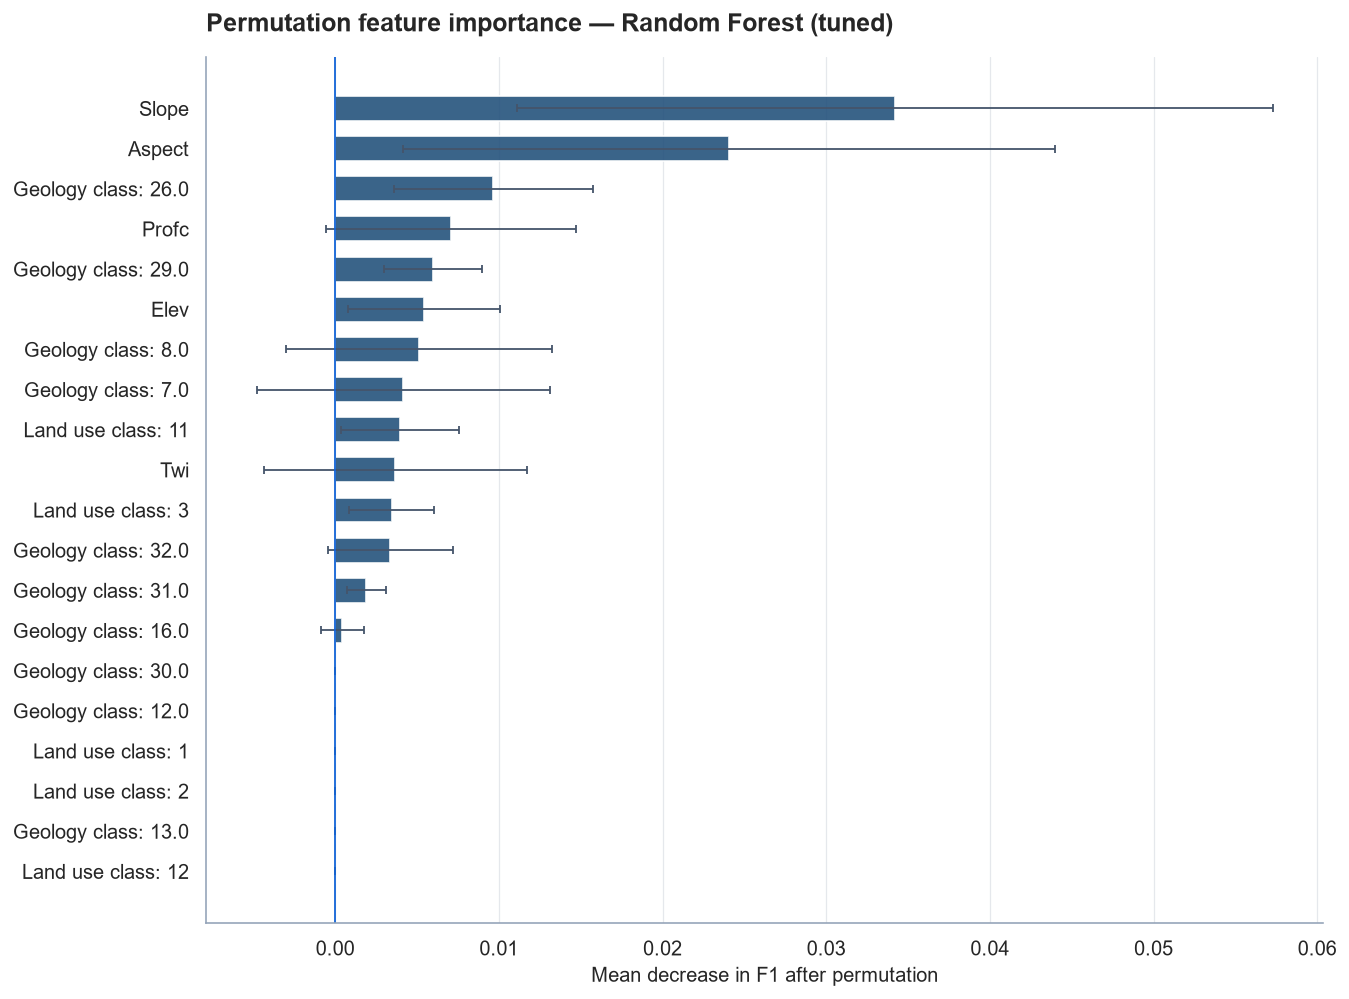

In [23]:
perm_result = permutation_importance(
    selected_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

perm_df = pd.DataFrame({
    "feature": X_test.columns,
    "display_feature": pretty_feature_names,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std,
})

perm_df = (
    perm_df
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

display(perm_df.head(20).round(4))

top_perm = perm_df.head(20).sort_values("importance_mean")

fig, ax = plt.subplots(figsize=(10.5, 7.8))
bars = ax.barh(
    top_perm["display_feature"],
    top_perm["importance_mean"],
    xerr=top_perm["importance_std"],
    color=PRIMARY,
    alpha=0.88,
    height=0.62,
    error_kw={"ecolor": SLATE, "capsize": 2, "elinewidth": 1},
)

polish_axes(
    ax,
    f"Permutation feature importance — {selected_name}",
    "Mean decrease in F1 after permutation",
    "",
)
ax.axvline(0, color="#1264D7", linewidth=1)
ax.grid(axis="y", visible=False)

fig.tight_layout()
save_figure(fig, "13_permutation_importance.png")
plt.show()


### 5.2 Built-in tree importance

,feature,display_feature,importance
4,continuous__slope,Slope,0.1866
0,continuous__aspect,Aspect,0.1503
5,continuous__spi,Spi,0.1229
2,continuous__planc,Planc,0.0953
6,continuous__twi,Twi,0.0911
1,continuous__elev,Elev,0.0881
3,continuous__profc,Profc,0.0508
9,categorical__geologi_8.0,Geology class: 8.0,0.0477
8,categorical__geologi_7.0,Geology class: 7.0,0.0269
19,categorical__geologi_32.0,Geology class: 32.0,0.0207


Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\14_builtin_feature_importance.png


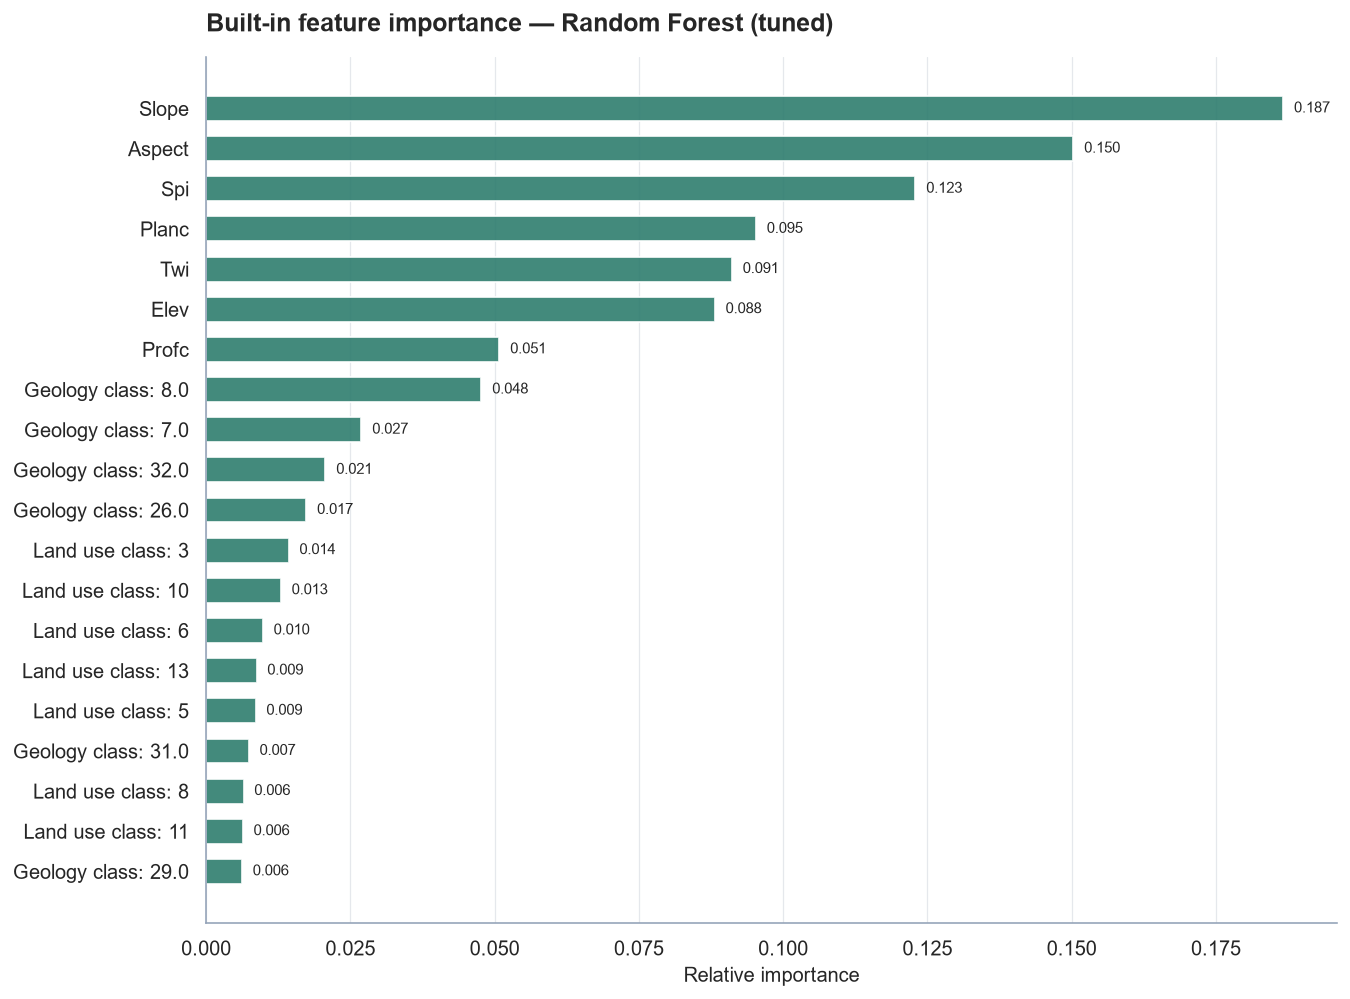

In [24]:
if hasattr(selected_model, "feature_importances_"):
    builtin_df = pd.DataFrame({
        "feature": X_train.columns,
        "display_feature": pretty_feature_names,
        "importance": selected_model.feature_importances_,
    }).sort_values("importance", ascending=False)

    display(builtin_df.head(20).round(4))

    top_builtin = builtin_df.head(20).sort_values("importance")

    fig, ax = plt.subplots(figsize=(10.5, 7.8))
    bars = ax.barh(
        top_builtin["display_feature"],
        top_builtin["importance"],
        color=SECONDARY,
        alpha=0.9,
        height=0.62,
    )

    for bar, value in zip(bars, top_builtin["importance"]):
        ax.text(
            value + top_builtin["importance"].max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            fontsize=8.5,
        )

    polish_axes(
        ax,
        f"Built-in feature importance — {selected_name}",
        "Relative importance",
        "",
    )
    ax.grid(axis="y", visible=False)

    fig.tight_layout()
    save_figure(fig, "14_builtin_feature_importance.png")
    plt.show()
else:
    print("The selected model does not provide built-in tree feature importance.")


### 5.3 Optional SHAP interpretation

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\15_shap_summary.png


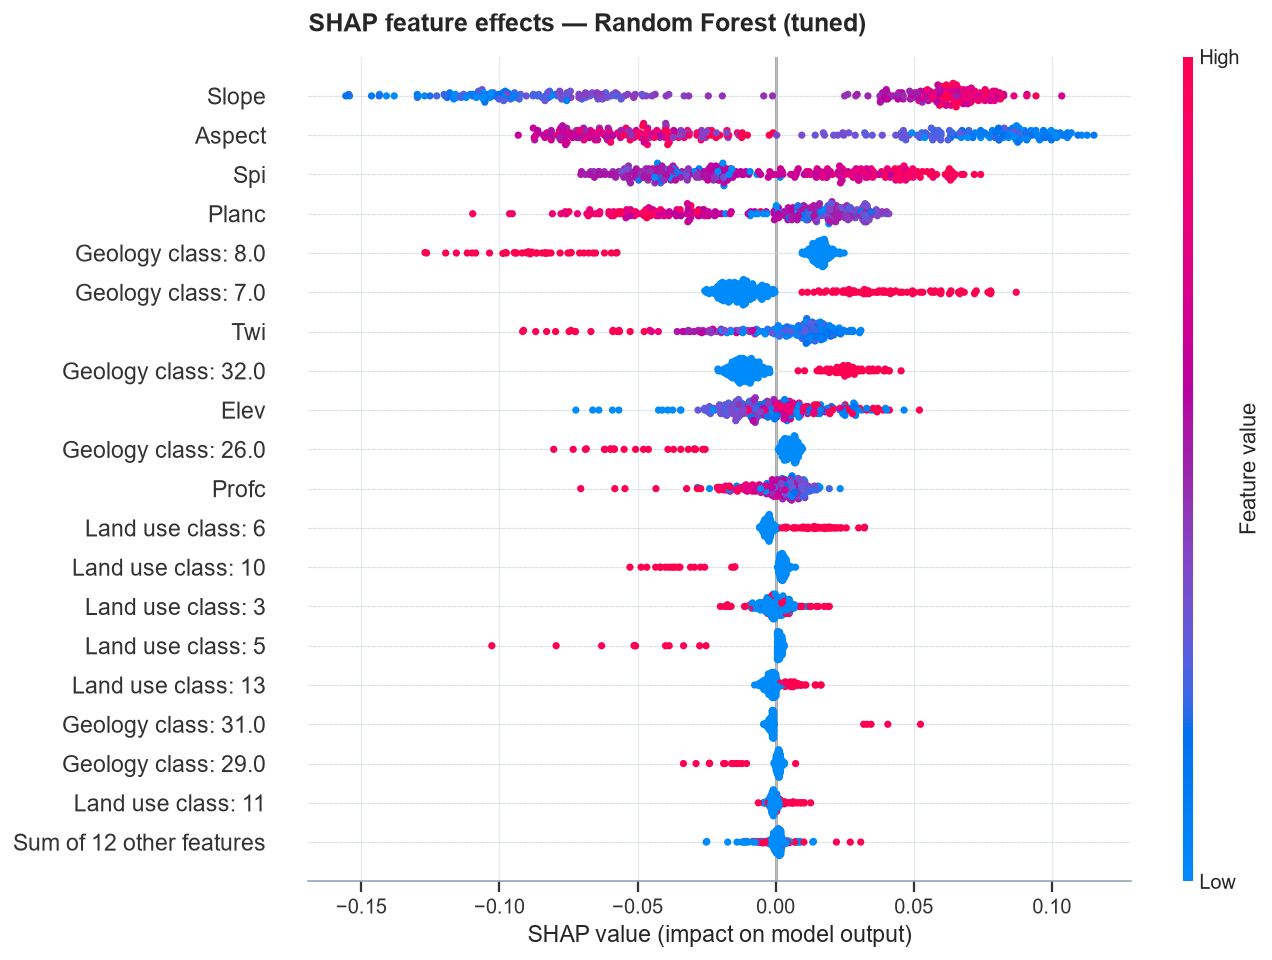

In [25]:
try:
    import shap

    if hasattr(selected_model, "feature_importances_"):
        X_shap = X_test.sample(
            n=min(1000, len(X_test)),
            random_state=RANDOM_STATE,
        )

        explainer = shap.TreeExplainer(selected_model)
        explanation = explainer(X_shap)

        # Binary Random Forest can return one SHAP array per class.
        if explanation.values.ndim == 3:
            explanation = explanation[:, :, 1]

        explanation.feature_names = pretty_feature_names

        shap.plots.beeswarm(
            explanation,
            max_display=20,
            show=False,
        )

        fig = plt.gcf()
        ax = plt.gca()
        ax.set_title(
            f"SHAP feature effects — {selected_name}",
            loc="left",
            pad=14,
            fontweight="bold",
        )
        fig.set_size_inches(10.5, 7.5)
        fig.tight_layout()
        save_figure(fig, "15_shap_summary.png")
        plt.show()

    else:
        print("SHAP TreeExplainer skipped because the selected model is not tree-based.")

except ImportError:
    print("SHAP is not installed. Install once if needed: pip install shap")
except Exception as e:
    print("SHAP plot could not be generated:", type(e).__name__, e)


## 6. Spatial cross-validation — robustness against spatial leakage

Random cross-validation can be optimistic when nearby samples share similar environmental conditions.

This section rebuilds the modelling inputs from the **full Indonesia CSV**, but uses the same modelling feature list defined earlier. Therefore `distriv` and `distroad` remain stored in the CSV while being excluded from the model.

The workflow creates **10 km spatial blocks** and compares:

- ordinary stratified random cross-validation, and
- stratified group cross-validation where entire spatial blocks are held out.

The preprocessor is **re-fitted inside every fold**, preventing preprocessing leakage.


In [26]:
if not FINAL_CSV.exists():
    raise FileNotFoundError(
        f"Final Indonesia CSV not found: {FINAL_CSV}"
    )

model_df = pd.read_csv(FINAL_CSV)

raw_feature_columns = X_train_raw.columns.tolist()

assert "distriv" not in raw_feature_columns
assert "distroad" not in raw_feature_columns

required_spatial_columns = (
    raw_feature_columns
    + ["X", "Y", "label"]
)

missing_required = [
    c for c in required_spatial_columns
    if c not in model_df.columns
]

if missing_required:
    raise ValueError(
        f"Missing columns required for spatial CV: {missing_required}"
    )

model_df = model_df.dropna(
    subset=required_spatial_columns
).reset_index(drop=True)

GRID_SIZE_M = 10_000

model_df["grid_x"] = (
    model_df["X"] // GRID_SIZE_M
).astype(int)

model_df["grid_y"] = (
    model_df["Y"] // GRID_SIZE_M
).astype(int)

model_df["spatial_block"] = (
    model_df["grid_x"].astype(str)
    + "_"
    + model_df["grid_y"].astype(str)
)

X_spatial_raw = model_df[
    raw_feature_columns
]

y_spatial = (
    model_df["label"]
    .astype(int)
)

groups = model_df[
    "spatial_block"
]

print("Rows used for spatial CV:", len(model_df))
print("Spatial blocks:", groups.nunique())
print("Class balance:")
print(y_spatial.value_counts())

print("\nSpatial-CV modelling factors:")
print(raw_feature_columns)

print("\nConfirmed excluded:")
print("distriv :", "distriv" not in raw_feature_columns)
print("distroad:", "distroad" not in raw_feature_columns)


Rows used for spatial CV: 1485
Spatial blocks: 26
Class balance:
label
1    743
0    742
Name: count, dtype: int64

Spatial-CV modelling factors:
['aspect', 'elev', 'planc', 'profc', 'slope', 'spi', 'twi', 'geologi', 'landuse']

Confirmed excluded:
distriv : True
distroad: True


### 6.1 Visualize spatial folds

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\16_spatial_cv_folds.png


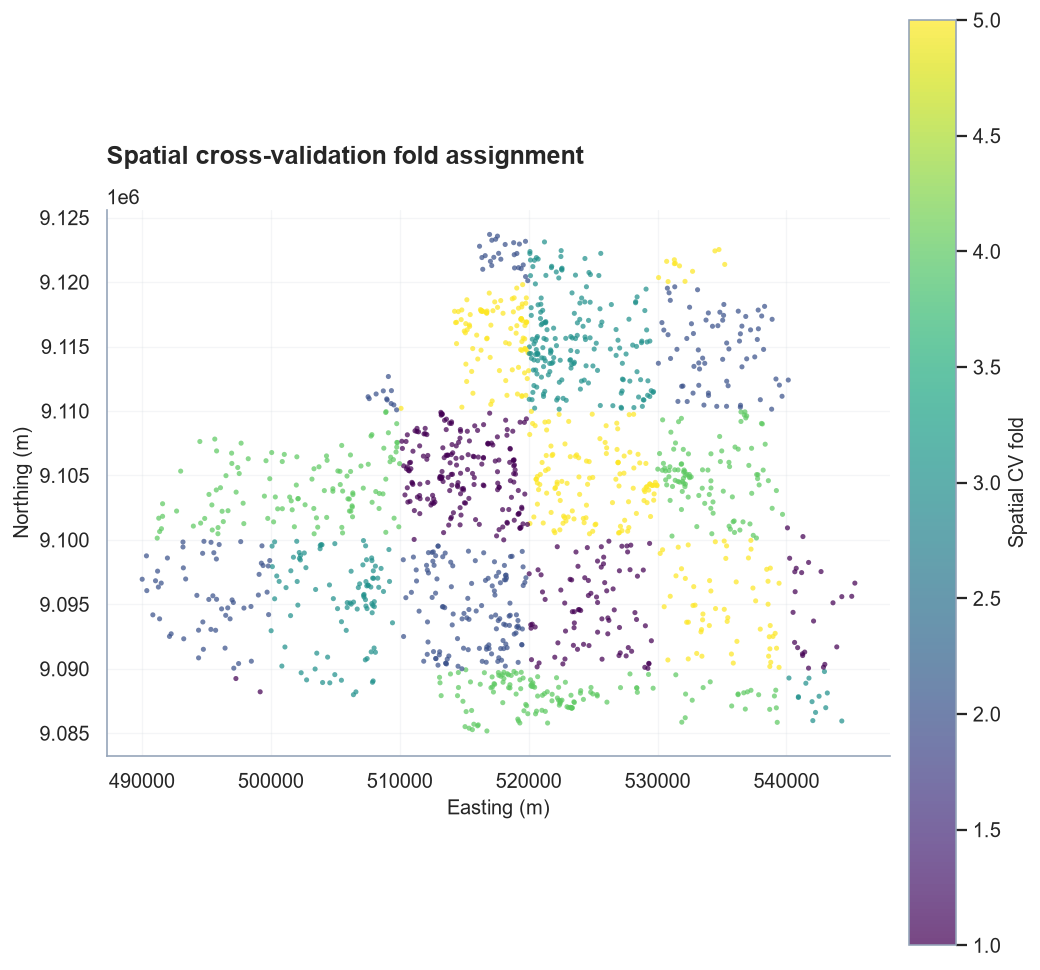

label,0,1,All
spatial_fold,,,
1,111,180,291
2,187,98,285
3,135,149,284
4,181,162,343
5,128,154,282
All,742,743,1485


In [27]:
spatial_cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

fold_assignment = np.full(
    len(model_df),
    -1,
    dtype=int,
)

for fold, (_, test_idx) in enumerate(
    spatial_cv.split(
        X_spatial_raw,
        y_spatial,
        groups=groups,
    ),
    start=1,
):
    fold_assignment[test_idx] = fold

model_df["spatial_fold"] = fold_assignment

fig, ax = plt.subplots(figsize=(8.3, 10.2))

scatter = ax.scatter(
    model_df["X"],
    model_df["Y"],
    c=model_df["spatial_fold"],
    cmap="viridis",
    s=8,
    alpha=0.72,
    linewidths=0,
)

cbar = fig.colorbar(
    scatter,
    ax=ax,
    shrink=0.72,
    pad=0.02,
)
cbar.set_label("Spatial CV fold")

polish_axes(
    ax,
    "Spatial cross-validation fold assignment",
    "Easting (m)",
    "Northing (m)",
)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.25)

fig.tight_layout()
save_figure(fig, "16_spatial_cv_folds.png")
plt.show()

display(
    pd.crosstab(
        model_df["spatial_fold"],
        model_df["label"],
        margins=True,
    )
)


### 6.2 Compare random CV and spatial CV

In [28]:
# Build a leakage-safe pipeline:
# each CV fold fits a fresh clone of the preprocessor and model.

cv_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", clone(selected_model)),
])

robustness_scoring = {
    "accuracy": "accuracy",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

random_cv_full = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

random_scores = cross_validate(
    cv_pipeline,
    X_spatial_raw,
    y_spatial,
    cv=random_cv_full,
    scoring=robustness_scoring,
    n_jobs=-1,
)

spatial_scores = cross_validate(
    cv_pipeline,
    X_spatial_raw,
    y_spatial,
    cv=spatial_cv,
    groups=groups,
    scoring=robustness_scoring,
    n_jobs=-1,
)

robustness_rows = []

for method, scores in [
    ("Random stratified CV", random_scores),
    ("Spatial grouped CV", spatial_scores),
]:
    for fold in range(N_SPLITS):
        robustness_rows.append({
            "method": method,
            "fold": fold + 1,
            "accuracy": scores["test_accuracy"][fold],
            "f1": scores["test_f1"][fold],
            "roc_auc": scores["test_roc_auc"][fold],
        })

robustness_df = pd.DataFrame(robustness_rows)

robustness_summary = (
    robustness_df
    .groupby("method")[["accuracy", "f1", "roc_auc"]]
    .agg(["mean", "std"])
)

display(robustness_summary.round(4))

accuracy             f1         roc_auc        
                         mean     std   mean     std    mean     std
method                                                              
Random stratified CV   0.6949  0.0211  0.707  0.0151  0.7638  0.0118
Spatial grouped CV     0.6578  0.0483  0.659  0.0774  0.7224  0.0707

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\17_random_vs_spatial_cv.png


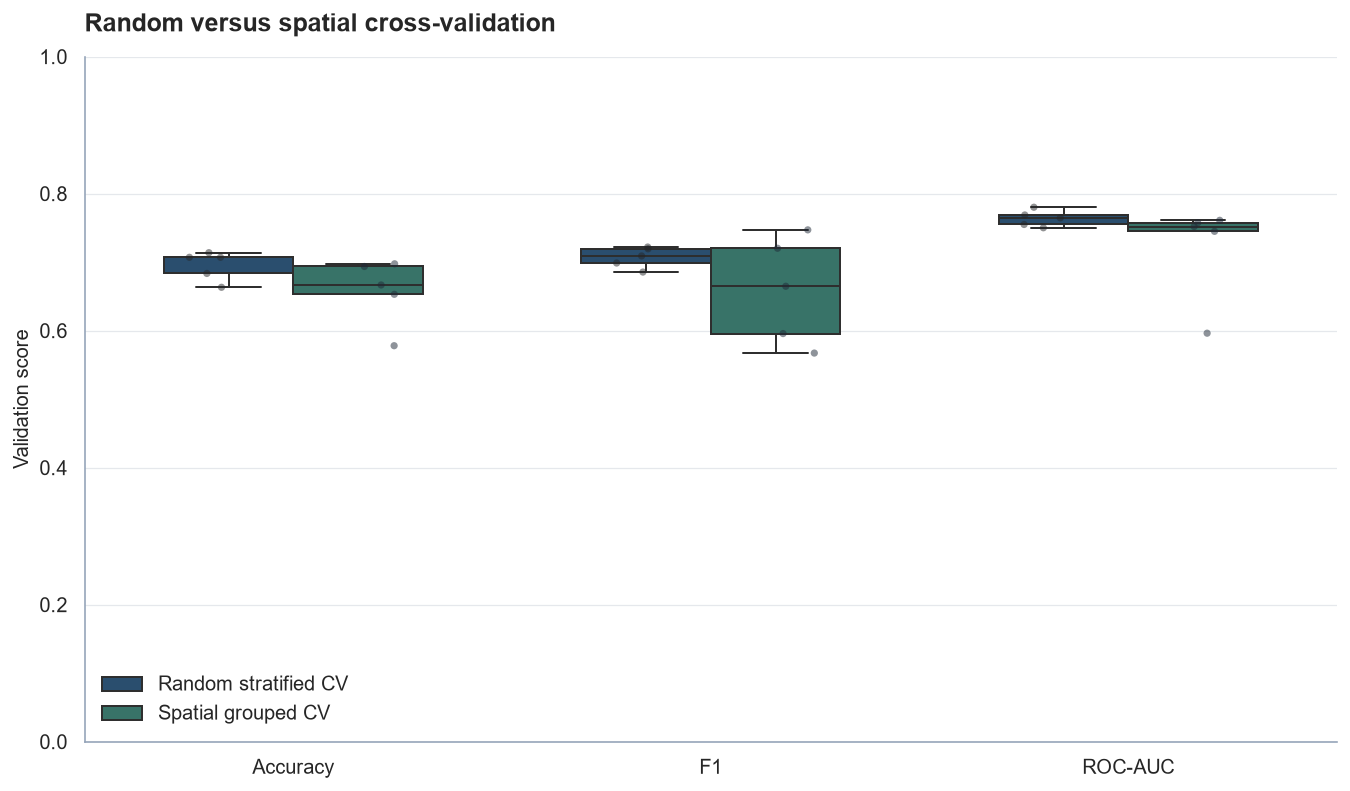

In [29]:
robustness_long = robustness_df.melt(
    id_vars=["method", "fold"],
    value_vars=["accuracy", "f1", "roc_auc"],
    var_name="metric",
    value_name="score",
)

metric_order = ["accuracy", "f1", "roc_auc"]
metric_display = {
    "accuracy": "Accuracy",
    "f1": "F1",
    "roc_auc": "ROC-AUC",
}

robustness_long["Metric"] = (
    robustness_long["metric"]
    .map(metric_display)
)

fig, ax = plt.subplots(figsize=(10.5, 6.2))

sns.boxplot(
    data=robustness_long,
    x="Metric",
    y="score",
    hue="method",
    order=[metric_display[m] for m in metric_order],
    palette=[PRIMARY, SECONDARY],
    width=0.62,
    linewidth=1.1,
    fliersize=0,
    ax=ax,
)

sns.stripplot(
    data=robustness_long,
    x="Metric",
    y="score",
    hue="method",
    order=[metric_display[m] for m in metric_order],
    dodge=True,
    color="#1F2937",
    size=4,
    alpha=0.5,
    legend=False,
    ax=ax,
)

polish_axes(
    ax,
    "Random versus spatial cross-validation",
    "",
    "Validation score",
)
ax.set_ylim(0, 1)
ax.legend(title="", loc="lower left")

fig.tight_layout()
save_figure(fig, "17_random_vs_spatial_cv.png")
plt.show()


## 7. Generalizing the models

Section 2.3 showed Random Forest and XGBoost reaching a training F1 of up to
1.00 while their cross-validated F1 stayed near 0.90 — a sign of overfitting
to the training folds. Section 6.2 then showed that switching from ordinary
random cross-validation to **spatial block cross-validation** drops ROC-AUC
from roughly 0.95 to roughly 0.94 and noticeably increases the fold-to-fold
variance, which suggests the random-split numbers are somewhat optimistic
because nearby training and test points share very similar terrain
conditions (spatial autocorrelation).

Note that a high ROC-AUC or an ROC curve's visual smoothness are **not**
evidence of overfitting either way — the curve's step-like shape is simply a
finite-sample artifact of sweeping a threshold across a limited test set.
Overfitting is diagnosed by comparing training performance against
validation/held-out performance, which is exactly what this section does.

This section re-tunes the tree ensembles to close that gap:

1. **Score hyperparameter search with spatial group CV**
   (`StratifiedGroupKFold` over 10 km blocks) instead of random
   `StratifiedKFold`, so the search itself is optimized for generalizing to
   unseen terrain rather than to randomly held-out rows.
2. **Narrow the search grid toward stronger regularization** — shallower
   trees, larger minimum leaf sizes, and explicit L1/L2/`gamma` terms for
   XGBoost — to close the train/validation gap seen in Section 2.3.
3. **Compare the regularized, spatially-tuned models against the originally
   tuned models** under both random CV and spatial CV.
4. **Prune near-zero-importance features** identified by permutation
   importance in Section 5.1.
5. **Refit the best-generalizing model** and update `selected_model` /
   `selected_name`, so Sections 8-9 save and report the generalized model
   rather than the originally tuned one.


### 7.1 Re-tune Random Forest and XGBoost with spatial-CV scoring

Each candidate is wrapped in a `Pipeline` with a freshly cloned preprocessor, fit on the **raw** spatial features (`X_spatial_raw`, `y_spatial`) built in Section 6.1, and scored with `spatial_cv` / `groups` so every hyperparameter choice is judged on unseen spatial blocks. This can take a few minutes.

In [30]:
# Narrower, more regularized search grids to curb the overfitting seen in
# Section 2.3, scored with StratifiedGroupKFold so that model selection
# itself targets generalization to unseen spatial blocks rather than
# unseen rows.

generalization_pipeline_rf = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1,
    )),
])

rf_param_dist_reg = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [4, 6, 8, 10],
    "model__min_samples_split": [5, 10, 20],
    "model__min_samples_leaf": [4, 8, 16],
    "model__max_features": ["sqrt", "log2"],
}

rf_search_spatial = RandomizedSearchCV(
    estimator=generalization_pipeline_rf,
    param_distributions=rf_param_dist_reg,
    n_iter=20,
    scoring="roc_auc",
    cv=spatial_cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)

rf_search_spatial.fit(X_spatial_raw, y_spatial, groups=groups)

print("Best regularized Random Forest parameters (spatial CV):")
print(rf_search_spatial.best_params_)
print("Best RF spatial-CV ROC-AUC:", round(rf_search_spatial.best_score_, 4))

xgb_search_spatial = None

if XGBOOST_AVAILABLE:
    generalization_pipeline_xgb = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", xgb.XGBClassifier(
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=1,
        )),
    ])

    xgb_param_dist_reg = {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [3, 4, 5, 6],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "model__subsample": [0.6, 0.8],
        "model__colsample_bytree": [0.6, 0.8],
        "model__min_child_weight": [3, 5, 8],
        "model__reg_alpha": [0, 0.1, 0.5, 1.0],
        "model__reg_lambda": [1.0, 2.0, 5.0],
        "model__gamma": [0, 0.1, 0.5],
    }

    xgb_search_spatial = RandomizedSearchCV(
        estimator=generalization_pipeline_xgb,
        param_distributions=xgb_param_dist_reg,
        n_iter=20,
        scoring="roc_auc",
        cv=spatial_cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1,
    )

    xgb_search_spatial.fit(X_spatial_raw, y_spatial, groups=groups)

    print("\nBest regularized XGBoost parameters (spatial CV):")
    print(xgb_search_spatial.best_params_)
    print("Best XGBoost spatial-CV ROC-AUC:", round(xgb_search_spatial.best_score_, 4))
else:
    print("XGBoost not installed - regularized XGBoost search skipped.")


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best regularized Random Forest parameters (spatial CV):
{'model__n_estimators': 200, 'model__min_samples_split': 20, 'model__min_samples_leaf': 16, 'model__max_features': 'log2', 'model__max_depth': 8}
Best RF spatial-CV ROC-AUC: 0.7292
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best regularized XGBoost parameters (spatial CV):
{'model__subsample': 0.6, 'model__reg_lambda': 2.0, 'model__reg_alpha': 1.0, 'model__n_estimators': 500, 'model__min_child_weight': 8, 'model__max_depth': 6, 'model__learning_rate': 0.01, 'model__gamma': 0, 'model__colsample_bytree': 0.6}
Best XGBoost spatial-CV ROC-AUC: 0.7216


### 7.2 Compare original vs. spatially-regularized models under random and spatial CV

The originally tuned estimators (`rf_search.best_estimator_`, `xgb_search.best_estimator_`) are wrapped in the same kind of preprocessing pipeline so the comparison is apples-to-apples, then every candidate is scored with **both** `cv` (random) and `spatial_cv` (spatial-block) splitters.

,model,cv_method,roc_auc_mean,roc_auc_std,f1_mean,f1_std
0,Random Forest (original tuned),Random CV,0.7638,0.0106,0.7070,0.0135
1,Random Forest (original tuned),Spatial CV,0.7224,0.0633,0.6590,0.0692
2,Random Forest (spatially regularized),Random CV,0.7564,0.0124,0.6954,0.0161
3,Random Forest (spatially regularized),Spatial CV,0.7292,0.0673,0.6658,0.0607
4,XGBoost (original tuned),Random CV,0.7603,0.0177,0.7064,0.0186
5,XGBoost (original tuned),Spatial CV,0.7135,0.0467,0.6574,0.0565
6,XGBoost (spatially regularized),Random CV,0.7596,0.0144,0.6972,0.0136
7,XGBoost (spatially regularized),Spatial CV,0.7216,0.0459,0.6531,0.0705


Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling\18_generalization_comparison.png


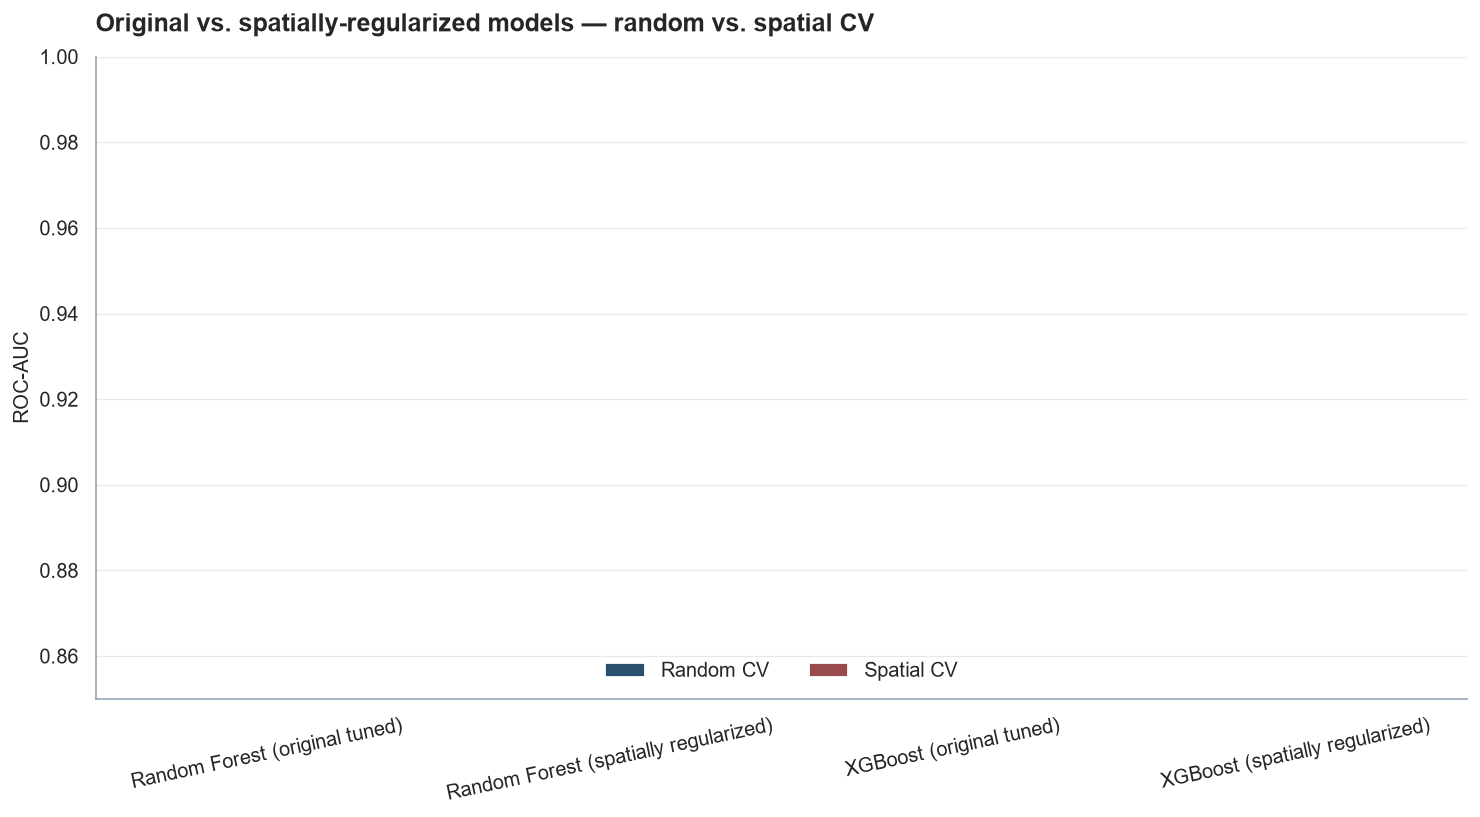

In [31]:
original_rf_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", clone(rf_search.best_estimator_)),
])

candidates_for_comparison = {
    "Random Forest (original tuned)": original_rf_pipeline,
    "Random Forest (spatially regularized)": rf_search_spatial.best_estimator_,
}

if XGBOOST_AVAILABLE:
    original_xgb_pipeline = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", clone(xgb_search.best_estimator_)),
    ])
    candidates_for_comparison["XGBoost (original tuned)"] = original_xgb_pipeline
    candidates_for_comparison["XGBoost (spatially regularized)"] = xgb_search_spatial.best_estimator_

comparison_scoring = {"roc_auc": "roc_auc", "f1": "f1"}

generalization_rows = []

for name, estimator in candidates_for_comparison.items():
    for cv_name, cv_splitter, cv_groups in [
        ("Random CV", cv, None),
        ("Spatial CV", spatial_cv, groups),
    ]:
        scores = cross_validate(
            estimator,
            X_spatial_raw,
            y_spatial,
            cv=cv_splitter,
            groups=cv_groups,
            scoring=comparison_scoring,
            n_jobs=-1,
        )
        generalization_rows.append({
            "model": name,
            "cv_method": cv_name,
            "roc_auc_mean": scores["test_roc_auc"].mean(),
            "roc_auc_std": scores["test_roc_auc"].std(),
            "f1_mean": scores["test_f1"].mean(),
            "f1_std": scores["test_f1"].std(),
        })

generalization_df = pd.DataFrame(generalization_rows)
display(generalization_df.round(4))

fig, ax = plt.subplots(figsize=(11.5, 6.4))

sns.barplot(
    data=generalization_df,
    x="model",
    y="roc_auc_mean",
    hue="cv_method",
    palette=[PRIMARY, DANGER],
    width=0.62,
    ax=ax,
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9, fontweight="bold")

polish_axes(
    ax,
    "Original vs. spatially-regularized models — random vs. spatial CV",
    "",
    "ROC-AUC",
)
ax.set_ylim(0.85, 1.0)
ax.tick_params(axis="x", rotation=12)
ax.legend(title="", ncol=2, loc="lower center")

fig.tight_layout()
save_figure(fig, "18_generalization_comparison.png")
plt.show()


### 7.3 Drop near-zero-importance features

`perm_df` (Section 5.1) already ranks every processed feature by its permutation importance. Features with an importance at or below zero add noise/variance without predictive value, so they are dropped before the final refit.

In [32]:
low_importance_features = perm_df.loc[
    perm_df["importance_mean"] <= 0, "feature"
].tolist()

print(f"Dropping {len(low_importance_features)} near-zero-importance feature(s):")
print(low_importance_features)

pruned_columns = [c for c in X_train.columns if c not in low_importance_features]

X_train_pruned = X_train[pruned_columns]
X_test_pruned = X_test[pruned_columns]

print(f"\nFeature count: {X_train.shape[1]} -> {X_train_pruned.shape[1]}")


Dropping 17 near-zero-importance feature(s):
['categorical__geologi_13.0', 'categorical__landuse_12', 'categorical__landuse_1', 'categorical__landuse_2', 'categorical__geologi_30.0', 'categorical__geologi_12.0', 'categorical__geologi_27.0', 'categorical__landuse_4', 'categorical__geologi_20.0', 'categorical__geologi_2.0', 'categorical__landuse_5', 'categorical__landuse_8', 'categorical__landuse_6', 'categorical__landuse_13', 'categorical__landuse_10', 'continuous__spi', 'continuous__planc']

Feature count: 31 -> 14


### 7.4 Refit the generalized model and update the final selection

Whichever candidate scored highest under **spatial** CV in Section 7.2 is refit on the pruned, processed training matrix and evaluated on the held-out test set, using the same `evaluate_binary_classifier` helper from Section 4. `selected_model` and `selected_name` are then updated so that Sections 8-9 save and report this generalized model instead of the originally tuned one.

In [33]:
best_spatial_row = (
    generalization_df[generalization_df["cv_method"] == "Spatial CV"]
    .sort_values("roc_auc_mean", ascending=False)
    .iloc[0]
)

print("Best-generalizing model under spatial CV:", best_spatial_row["model"])
print(best_spatial_row[["roc_auc_mean", "roc_auc_std", "f1_mean", "f1_std"]])

if "XGBoost" in best_spatial_row["model"]:
    generalized_model = clone(xgb_search_spatial.best_estimator_.named_steps["model"])
    generalized_name = "XGBoost (spatially regularized)"
else:
    generalized_model = clone(rf_search_spatial.best_estimator_.named_steps["model"])
    generalized_name = "Random Forest (spatially regularized)"

generalized_model.fit(X_train_pruned, y_train)

generalized_test_results = evaluate_binary_classifier(
    generalized_model,
    X_test_pruned,
    y_test,
)
generalized_test_results["model"] = generalized_name

print("\nHeld-out test performance of the generalized model:")
display(
    pd.DataFrame([generalized_test_results])
    .set_index("model")
    .round(4)
)

print("\nFor comparison, the originally selected model on the same held-out test set:")
display(final_results_df.loc[[selected_name]].round(4))

# Update the final selection so downstream sections save/report this model.
selected_model = generalized_model
selected_name = generalized_name

print(
    f"\n'selected_model' and 'selected_name' updated to "
    f"'{selected_name}' for saving in Section 8."
)


Best-generalizing model under spatial CV: Random Forest (spatially regularized)
roc_auc_mean    0.729175
roc_auc_std     0.067295
f1_mean         0.665834
f1_std          0.060707
Name: 3, dtype: object

Held-out test performance of the generalized model:


,accuracy,precision,recall,specificity,f1,mcc,tss,roc_auc,pr_auc,brier
model,,,,,,,,,,
Random Forest (spatially regularized),0.7071,0.7013,0.7248,0.6892,0.7129,0.4143,0.414,0.7753,0.7659,0.196



For comparison, the originally selected model on the same held-out test set:


,accuracy,precision,recall,specificity,f1,mcc,tss,roc_auc,pr_auc,brier
model,,,,,,,,,,
Random Forest (tuned),0.6869,0.6867,0.6913,0.6824,0.689,0.3737,0.3737,0.7729,0.7493,0.1958



'selected_model' and 'selected_name' updated to 'Random Forest (spatially regularized)' for saving in Section 8.


## 8. Save the selected model and evaluation results

The saved model is the candidate selected in Section 7.4 as the best-generalizing model under spatial cross-validation. The preprocessor is saved separately because prediction on new spatial data must apply exactly the same transformations.

In [34]:
# ==========================================================
# Save selected model, preprocessor, and modelling results
# ==========================================================

from datetime import datetime, timezone
import json
import joblib


MODEL_DIR = PROCESSED_DIR / "models"
MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATH = (
    MODEL_DIR /
    "indonesia_selected_model.pkl"
)

PREPROCESSOR_PATH = (
    MODEL_DIR /
    "indonesia_preprocessor.pkl"
)

RESULTS_PATH = (
    MODEL_DIR /
    "indonesia_model_results.json"
)

FEATURES_PATH = (
    MODEL_DIR /
    "indonesia_model_features.json"
)


# ----------------------------------------------------------
# Resolve the CV score associated with the selected model
# ----------------------------------------------------------

selected_training_cv_f1 = None


# Exact match
if selected_name in tuned_cv_f1:

    selected_training_cv_f1 = float(
        tuned_cv_f1[selected_name]
    )


# Spatially-regularized XGBoost came from the tuned XGBoost
elif (
    "XGBoost" in selected_name
    and xgb_search is not None
):

    selected_training_cv_f1 = float(
        xgb_search.best_score_
    )


# Random Forest fallback
elif "Random Forest" in selected_name:

    selected_training_cv_f1 = float(
        rf_search.best_score_
    )


# ----------------------------------------------------------
# Spatial CV summary
# ----------------------------------------------------------

spatial_cv_summary = None

if (
    "robustness_df" in globals()
    and robustness_df is not None
    and len(robustness_df) > 0
):

    spatial_rows = robustness_df[
        robustness_df["method"]
        .astype(str)
        .str.contains(
            "spatial",
            case=False,
            na=False
        )
    ]

    if len(spatial_rows) > 0:

        spatial_cv_summary = {
            "accuracy_mean":
                float(spatial_rows["accuracy"].mean()),

            "f1_mean":
                float(spatial_rows["f1"].mean()),

            "roc_auc_mean":
                float(spatial_rows["roc_auc"].mean()),
        }


# ----------------------------------------------------------
# Save model files
# ----------------------------------------------------------

joblib.dump(
    selected_model,
    MODEL_PATH
)

joblib.dump(
    preprocessor,
    PREPROCESSOR_PATH
)


# ----------------------------------------------------------
# Results summary
# ----------------------------------------------------------

results_summary = {

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "random_state":
        RANDOM_STATE,

    "selected_model":
        selected_name,

    "selection_rule":
        (
            "Model selected following tuned cross-validation "
            "and spatial robustness assessment"
        ),

    "selected_training_cv_f1":
        selected_training_cv_f1,

    "train_rows":
        int(len(X_train)),

    "test_rows":
        int(len(X_test)),

    "processed_feature_count":
        int(X_train.shape[1]),

    "raw_factor_count":
        int(X_train_raw.shape[1]),

    "excluded_at_modelling_stage":
        MODEL_EXCLUDE_FACTORS,

    "model_raw_factors":
        model_factor_columns,


    # --------------------------------------
    # Baseline model CV results
    # --------------------------------------

    "baseline_cv":
        cv_results_df.to_dict(
            orient="records"
        ),


    # --------------------------------------
    # Tuned model CV
    # --------------------------------------

    "tuned_cv_f1": {
        k: float(v)
        for k, v
        in tuned_cv_f1.items()
    },


    # --------------------------------------
    # Held-out test
    # --------------------------------------

    "heldout_test": (
        final_results_df
        .reset_index()
        .to_dict(
            orient="records"
        )
    ),


    # --------------------------------------
    # Spatial CV
    # --------------------------------------

    "spatial_cv": (
        robustness_df.to_dict(
            orient="records"
        )
        if "robustness_df" in globals()
        else None
    ),

    "spatial_cv_summary":
        spatial_cv_summary,


    # --------------------------------------
    # Hyperparameters
    # --------------------------------------

    "rf_best_params":
        rf_search.best_params_,

    "xgb_best_params": (
        xgb_search.best_params_
        if xgb_search is not None
        else None
    ),
}


# ----------------------------------------------------------
# Save modelling feature definition
# ----------------------------------------------------------

feature_metadata = {
    "source_dataset": str(FINAL_CSV),
    "full_continuous_factors": FULL_CONTINUOUS_FACTORS,
    "full_categorical_factors": FULL_CATEGORICAL_FACTORS,
    "excluded_at_modelling_stage": MODEL_EXCLUDE_FACTORS,
    "model_continuous_factors": model_continuous_factors,
    "model_categorical_factors": model_categorical_factors,
    "model_raw_factors": model_factor_columns,
    "processed_features": X_train.columns.tolist(),
}

FEATURES_PATH.write_text(
    json.dumps(
        feature_metadata,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)


# ----------------------------------------------------------
# Save results JSON
# ----------------------------------------------------------

RESULTS_PATH.write_text(

    json.dumps(
        results_summary,
        indent=2,
        default=str
    ),

    encoding="utf-8"
)


print("\nMODEL ARTIFACTS SAVED")

print(
    "Saved model       :",
    MODEL_PATH
)

print(
    "Saved preprocessor:",
    PREPROCESSOR_PATH
)

print(
    "Saved results     :",
    RESULTS_PATH
)

print(
    "Saved feature list:",
    FEATURES_PATH
)

print(
    "\nSelected model:",
    selected_name
)

print(
    "Training CV F1:",
    selected_training_cv_f1
)

if spatial_cv_summary is not None:

    print(
        "Spatial CV F1:",
        round(
            spatial_cv_summary[
                "f1_mean"
            ],
            4
        )
    )


MODEL ARTIFACTS SAVED
Saved model       : D:\PROJECTS\Landslide_prediction\data\processed\models\indonesia_selected_model.pkl
Saved preprocessor: D:\PROJECTS\Landslide_prediction\data\processed\models\indonesia_preprocessor.pkl
Saved results     : D:\PROJECTS\Landslide_prediction\data\processed\models\indonesia_model_results.json
Saved feature list: D:\PROJECTS\Landslide_prediction\data\processed\models\indonesia_model_features.json

Selected model: Random Forest (spatially regularized)
Training CV F1: 0.7050383896964886
Spatial CV F1: 0.659


In [35]:
# ==========================================================
# Verify the saved Indonesia model artifacts
# ==========================================================

print("Selected model:", selected_name)
print("Model object type:", type(selected_model).__name__)

print("\nRaw factors used by the Indonesia model:")
for factor in model_factor_columns:
    print(" -", factor)

print("\nExcluded only at modelling stage:")
for factor in MODEL_EXCLUDE_FACTORS:
    print(" -", factor)

print("\nFull source CSV still contains the excluded factors:")
print(
    full_df[
        MODEL_EXCLUDE_FACTORS
    ].head()
)


Selected model: Random Forest (spatially regularized)
Model object type: RandomForestClassifier

Raw factors used by the Indonesia model:
 - aspect
 - elev
 - planc
 - profc
 - slope
 - spi
 - twi
 - geologi
 - landuse

Excluded only at modelling stage:
 - distriv
 - distroad

Full source CSV still contains the excluded factors:
      distriv    distroad
0  679.000000   10.000000
1  739.299988   28.299999
2  702.099976  222.000000
3  376.399994  557.299988
4   70.000000  493.399994


In [37]:
# Final safety checks

assert "distriv" in full_df.columns
assert "distroad" in full_df.columns

assert "distriv" not in X_train_raw.columns
assert "distroad" not in X_train_raw.columns

assert "distriv" not in X_test_raw.columns
assert "distroad" not in X_test_raw.columns

print(
    "Verified: distance-to-river and distance-to-road are preserved "
    "in the full Indonesia dataset but excluded from model inputs."
)


Verified: distance-to-river and distance-to-road are preserved in the full Indonesia dataset but excluded from model inputs.


In [38]:
# Optional: display the final saved paths again

print("Indonesia modelling outputs")
print("----------------------------")
print("Model       :", MODEL_PATH)
print("Preprocessor:", PREPROCESSOR_PATH)
print("Results     :", RESULTS_PATH)
print("Features    :", FEATURES_PATH)
print("Figures     :", FIGURE_DIR)


Indonesia modelling outputs
----------------------------
Model       : D:\PROJECTS\Landslide_prediction\data\processed\models\indonesia_selected_model.pkl
Preprocessor: D:\PROJECTS\Landslide_prediction\data\processed\models\indonesia_preprocessor.pkl
Results     : D:\PROJECTS\Landslide_prediction\data\processed\models\indonesia_model_results.json
Features    : D:\PROJECTS\Landslide_prediction\data\processed\models\indonesia_model_features.json
Figures     : D:\PROJECTS\Landslide_prediction\data\processed\figures\indonesia_modeling


## Indonesia modelling outputs

The notebook produces the same main evaluation outputs as the Kerala modelling workflow:

1. Baseline 5-fold CV results.
2. Random Forest and XGBoost hyperparameter tuning.
3. Held-out test metrics.
4. Confusion matrices.
5. ROC and Precision–Recall curves.
6. Calibration and Brier score.
7. Learning-curve analysis.
8. Permutation importance and optional SHAP interpretation.
9. Random vs. spatial cross-validation.
10. Spatially regularized generalization comparison.
11. Saved Indonesia model, preprocessor, results, feature definition, and thesis-ready figures.

### Important feature rule

The full Indonesia dataset retains `distriv` and `distroad`.

The modelling feature set excludes only:

- `distriv` — distance to river
- `distroad` — distance to road
